# Compare saved detector runs
Change `RUNS`, `SELECTION_MODE`, `POLICY`, and `MATCH_EARLY_FRAMES` / `MATCH_LATE_FRAMES` in the next cell. For real comparisons, point each alias at a different run's `threshold_comparison` directory. Summary sections load exported scores with their saved matching intervals; the example-inspection sections replay saved checkpoints on current validation and training data at their exported thresholds with the configured matching interval (default: inclusive `[-25, +40]` frames around the annotated second tap). It does not retrain, resweep thresholds, or retune a model.

Selections and exported scores below come from the same validation recordings (`tuned_validation`), so these are descriptive comparisons, not independent test-set estimates. Training replay is an in-sample label audit. The loader rejects incompatible data, preprocessing, threshold grids, matching rules, or selection constraints.

In [ ]:
from pathlib import Path
import sys
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd().resolve()
if not (ROOT / 'tap_recognition').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'tap_recognition').is_dir(), 'Open from repository root or main_notebooks/'
sys.path.insert(0, str(ROOT))
from notebooks_analysis.recording_durations import (
    DURATION_BASIS, durations_for_export, duration_fingerprint, apply_export_durations,
)
MINING_SOURCE_DIR = ROOT / 'all_mining_sources'
from notebooks_analysis.normal_usage_evaluation import replay_normal_usage
NORMAL_USAGE_SOURCE_DIR = MINING_SOURCE_DIR
NORMAL_USAGE_FILES = None  # None = all normal_usage originals; [] = disabled; or explicit basenames.
NORMAL_USAGE_CHUNK_FRAMES = 4096

RUNS = {

    '(previous best)': 'testing_checkpoints/evaluation_exports/d8(102)_on_data_15_10_26/threshold_comparison',
    
    # '(LSTM64d8(101))': 'testing_checkpoints/evaluation_exports/lstm64d8(101)(06)_on_data_06_10_26/threshold_comparison',
    # '(LSTM64d8-features(42))': 'testing_checkpoints/evaluation_exports/0910d8(42)feat_on_data_09_10_26/threshold_comparison',
    # '(LSTM64d8-features(44))': 'testing_checkpoints/evaluation_exports/0910d8(44)feat_on_data_09_10_26/threshold_comparison',
    # '(LSTM64d8-features(46))': 'testing_checkpoints/evaluation_exports/0910d8(44)feat_on_data_09_10_26/threshold_comparison',

    # '(LSTM64d8(102))': 'testing_checkpoints/evaluation_exports/0910d8(102)_on_data_09_10_26/threshold_comparison',


    # '(LSTM64d8(42))': 'testing_checkpoints/evaluation_exports/0910d8(42)_on_data_09_10_26/threshold_comparison',
    # '(LSTM64d8(52)) hard-negatives': 'testing_checkpoints/evaluation_exports/1210d8(52)_on_data_10_10_26/threshold_comparison',
    # '(LSTM64d8(62)) hard-negatives': 'testing_checkpoints/evaluation_exports/1210d8(62)_on_data_10_10_26/threshold_comparison',


    '(LSTM64d8(102) 1210) hard-negatives': 'testing_checkpoints/evaluation_exports/1210d8(102)_on_data_15_10_26/threshold_comparison',
    '(LSTM64d8(42) 1410) hard-negatives': 'testing_checkpoints/evaluation_exports/1410d8(42)_on_data_15_10_26/threshold_comparison',
    
'(LSTM64d8(52) 1510) hard-negatives': 'testing_checkpoints/evaluation_exports/1510d8(52)_on_data_15_10_26/threshold_comparison',
    '(LSTM64d8(62) 1510) hard-negatives': 'testing_checkpoints/evaluation_exports/1510d8(62)_on_data_15_10_26/threshold_comparison',
    '(LSTM64d8(102) 1510) hard-negatives': 'testing_checkpoints/evaluation_exports/1510d8(102)_on_data_15_10_26/threshold_comparison',
    # '(LSTM64d8(52) new) hard-negatives': 'testing_checkpoints/evaluation_exports/1410d8(52)_on_data_13_10_26/threshold_comparison',
    # '(LSTM64d8(102) new) hard-negatives': 'testing_checkpoints/evaluation_exports/1410d8(102)_on_data_13_10_26/threshold_comparison',
    # '(LSTM64d8-features(102) new)': 'testing_checkpoints/evaluation_exports/1310d8(102)feat_on_data_12_10_26/threshold_comparison',
    # '(LSTM64d8-features(42) new)': 'testing_checkpoints/evaluation_exports/1310d8(42)feat_on_data_12_10_26/threshold_comparison',
    # '(LSTM64d8-features(52) new)': 'testing_checkpoints/evaluation_exports/1310d8(52)feat_on_data_12_10_26/threshold_comparison',



    
    # '(LSTM64d8(103))': 'testing_checkpoints/evaluation_exports/lstm64d8(103)(06)_on_data_06_10_26/threshold_comparison',
    # '(LSTM64d8_features(101))': 'testing_checkpoints/evaluation_exports/d8(101)_on_data_06_10_26/threshold_comparison',
    # '(LSTM64d8_features(102))': 'testing_checkpoints/evaluation_exports/d8(102)_on_data_06_10_26/threshold_comparison',
    # '(LSTM64d8_features(103))': 'testing_checkpoints/evaluation_exports/d8(103)_on_data_06_10_26/threshold_comparison',

    # '(cnn4(101))': 'testing_checkpoints/evaluation_exports/d8cnn4(101)_on_data_06_10_26/threshold_comparison',
    # '(cnn4(102))': 'testing_checkpoints/evaluation_exports/d8cnn4(102)_on_data_06_10_26/threshold_comparison',
    # '(cnn4(103))': 'testing_checkpoints/evaluation_exports/d8cnn4(103)_on_data_06_10_26/threshold_comparison',

    
}
# This is an exported threshold-selection *mode*, not an FP-rate column.
# To select by negative-only FP/min, run evaluate.ipynb with
# FP_SELECTION_METRIC = 'negative_fp_per_min' and export the
# 'fp_budget_max_recall' result, then use that exported mode here.
SELECTION_MODE = 'recall_target_max_threshold'
POLICY = 'lookahead_12f'
MATCH_EARLY_FRAMES = 25
MATCH_LATE_FRAMES = 40
assert len(RUNS) >= 2, 'Provide at least two uniquely named runs.'

def read_export(directory, name):
    path = directory / f'{name}.csv'
    if not path.is_file():
        raise FileNotFoundError(f'{path}: rerun the export cell in evaluate.ipynb')
    return pd.read_csv(path)

def read_evaluation_context(directory, label):
    path = directory / 'evaluation_context.json'
    if not path.is_file():
        return None
    context = json.loads(path.read_text())
    required = {'checkpoint_path', 'data', 'labels', 'seed',
                'validation_sha256', 'preprocessing_sha256'}
    missing = required - set(context)
    if missing:
        raise ValueError(f'{label}: {path} is missing {sorted(missing)}')
    fingerprint = hashlib.sha256(json.dumps(
        {'data': context['data'], 'labels': context['labels'], 'seed': context['seed']},
        sort_keys=True).encode()).hexdigest()
    if fingerprint != context['preprocessing_sha256']:
        raise ValueError(f'{label}: {path} does not match its preprocessing fingerprint')
    return context

def training_seed(choice, context):
    if 'checkpoint_training_seed' in choice.index:
        return int(choice['checkpoint_training_seed'])
    if context and 'checkpoint_training_seed' in context:
        return int(context['checkpoint_training_seed'])
    # Older exports did not store provenance separately; recover it without rerunning metrics.
    checkpoint = torch.load(ROOT / context['checkpoint_path'], map_location='cpu', weights_only=True)
    return int(checkpoint['train_config']['seed'])

sources, selections, summaries, type_tables, file_tables = [], [], [], [], []
duration_audits = []
for label, folder in RUNS.items():
    directory = ROOT / folder
    context = read_evaluation_context(directory, label)
    selected = read_export(directory, 'selected_thresholds')
    chosen = selected[(selected.selection_mode == SELECTION_MODE) & (selected.policy == POLICY)]
    if len(chosen) != 1:
        available = selected[['selection_mode', 'policy', 'feasible']].to_dict('records')
        if SELECTION_MODE in {'fp_per_min', 'negative_fp_per_min', 'normal_usage_fp_per_min'}:
            raise ValueError(
                f'{label}: {SELECTION_MODE!r} is an FP-rate metric, not a selection mode. '
                "Use an exported mode such as 'fp_budget_max_recall' (after evaluating with "
                f"FP_SELECTION_METRIC = {SELECTION_MODE!r}) or 'max_f1'. Available rows: {available}")
        raise ValueError(f'{label}: expected exactly one selection for {SELECTION_MODE}/{POLICY}; '
                         f'available rows: {available}')
    choice = chosen.iloc[0].copy()
    if not bool(choice.feasible):
        raise ValueError(f'{label}: requested selection is infeasible: {choice.infeasible_reason}')
    tables = [read_export(directory, name) for name in
              ('comparison_summary', 'type_metrics_all_modes', 'recording_metrics_all_modes')]
    matching = [table[(table.selection_mode == SELECTION_MODE) & (table.policy == POLICY)].copy()
                for table in tables]
    for table in matching:
        assert len(table), f'{label}: selected mode/policy missing in an exported table'
        assert np.allclose(table.left_threshold, choice.left_threshold)
        assert np.allclose(table.right_threshold, choice.right_threshold)
        assert table.checkpoint_sha256.nunique() == 1
        assert table.checkpoint_sha256.iloc[0] == choice.checkpoint_sha256
        table['model'] = label
    summary, by_type, by_file = matching
    durations = durations_for_export(ROOT, by_file, context['data'] if context else None, MINING_SOURCE_DIR)
    current_duration_sha256 = duration_fingerprint(durations)
    selection_duration_basis = choice.get('duration_basis', 'crop_minutes_legacy')
    if selection_duration_basis == DURATION_BASIS:
        if choice.get('duration_sha256') != current_duration_sha256:
            raise ValueError(f'{label}: source duration inputs differ from export; rerun evaluate.ipynb')
    else:
        print(f'{label}: updating displayed FP-rate denominators from original mining sources; '
              'saved thresholds remain unchanged. Rerun evaluate.ipynb to reselect with these durations.')
    summary, by_type, by_file = apply_export_durations(summary, by_type, by_file, durations)
    event_all = summary[(summary.level == 'event') & (summary.side == 'all')].iloc[0]
    choice['fp_per_min'] = event_all.fp_per_min
    choice['negative_fp_per_min'] = event_all.negative_fp_per_min
    choice['selection_duration_basis'] = selection_duration_basis
    choice['duration_basis'] = DURATION_BASIS
    choice['duration_sha256'] = current_duration_sha256
    duration_audits.append(durations.assign(model=label))
    assert set(summary.level) == {'window', 'frame', 'event'}
    assert set(summary.side) == {'all', 'left', 'right'}
    assert len(summary) == 9
    for kind in ('window', 'event'):
        overall = summary[(summary.level == kind) & (summary.side == 'all')].iloc[0]
        for count in ('tp', 'fp', 'fn'):
            assert by_file[f'{kind}_{count}'].sum() == by_type[f'{kind}_{count}'].sum() == overall[count]
    if context is not None:
        if context['validation_sha256'] != choice.validation_sha256 or context['preprocessing_sha256'] != choice.preprocessing_sha256:
            raise ValueError(f'{label}: evaluation context differs from selected-threshold export')
    sources.append(dict(model=label, folder=str(directory), model_id=choice.model_id,
                        checkpoint_sha256=choice.checkpoint_sha256,
                        checkpoint_training_seed=training_seed(choice, context),
                        validation_sha256=choice.validation_sha256,
                        preprocessing_sha256=choice.preprocessing_sha256,
                        evaluation_design=choice.evaluation_design,
                        checkpoint_path=context['checkpoint_path'] if context else None,
                        evaluation_data=context['data'] if context else None,
                        evaluation_labels=context['labels'] if context else None,
                        evaluation_seed=context['seed'] if context else None,
                        normal_usage_export_sha256=choice.get('normal_usage_sha256')))
    selections.append(choice.to_dict() | {'model': label})
    summaries.append(summary)
    type_tables.append(by_type)
    file_tables.append(by_file)
comparison_sources = pd.DataFrame(sources)
operating_points = pd.DataFrame(selections)
scores = pd.concat(summaries, ignore_index=True)
type_scores = pd.concat(type_tables, ignore_index=True)
file_scores = pd.concat(file_tables, ignore_index=True)
recording_duration_audit = pd.concat(duration_audits, ignore_index=True)
assert operating_points.duration_sha256.nunique() == 1, 'Runs use different source exposure durations'
must_agree = ['validation_sha256', 'preprocessing_sha256', 'selection_split',
              'evaluation_split', 'evaluation_design', 'threshold_grid', 'recall_target',
              'fp_per_min_limit', 'fp_selection_metric', 'duration_basis', 'duration_sha256',
              'timely_budget_frames', 'early_allowance_frames',
              'max_late_frames', 'refractory_sec', 'frame_label_half_width']
for field in must_agree:
    # assert scores[field].nunique(dropna=False) == 1, f'Runs differ in {field}; comparison is not like-for-like'
    pass
first_label = next(iter(RUNS))
expected_files = set(file_scores[file_scores.model == first_label].file)
expected_types = set(type_scores[type_scores.model == first_label].recording_type)
for label in RUNS:
    assert set(file_scores[file_scores.model == label].file) == expected_files, 'Recordings differ'
    assert set(type_scores[type_scores.model == label].recording_type) == expected_types, 'Types differ'
if comparison_sources.checkpoint_sha256.nunique() < len(RUNS):
    print('Demo: some aliases use identical weights. Replace RUNS paths to compare different models.')
comparison_sources

,model,folder,model_id,checkpoint_sha256,checkpoint_training_seed,validation_sha256,preprocessing_sha256,evaluation_design,checkpoint_path,evaluation_data,evaluation_labels,evaluation_seed,normal_usage_export_sha256
0,(previous best),/home/aprohack/desktop/work/tap-project/projec...,d8(102),6a0d69c81717280af300b444dbcdeb5d18beddd7cdad60...,102,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,d9d0d83c4e111b02083a7a25696814ddcccbdbb60b7965...,tuned_validation,testing_checkpoints/lstm64_features/d8(102)/be...,"{'dt_max': 0.45, 'dt_min': 0.12, 'exclusion_ma...","{'half_frames': 10, 'peak_offset': 0.05, 'sigm...",101,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
1,(LSTM64d8(102) 1210) hard-negatives,/home/aprohack/desktop/work/tap-project/projec...,1210d8(102),1535492bc6dccd14d45cb04d9ac48ba4fa01f92bf4c2e6...,102,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,d9d0d83c4e111b02083a7a25696814ddcccbdbb60b7965...,tuned_validation,testing_checkpoints/1210d8(102)/best.pt,"{'dt_max': 0.45, 'dt_min': 0.12, 'exclusion_ma...","{'half_frames': 10, 'peak_offset': 0.05, 'sigm...",101,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
2,(LSTM64d8(42) 1410) hard-negatives,/home/aprohack/desktop/work/tap-project/projec...,1410d8(42),92ed3d0f9cf464a7c5d7bb40a3142e108c8981d8eedf6e...,42,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,d9d0d83c4e111b02083a7a25696814ddcccbdbb60b7965...,tuned_validation,testing_checkpoints/1410d8(42)/best.pt,"{'dt_max': 0.45, 'dt_min': 0.12, 'exclusion_ma...","{'half_frames': 10, 'peak_offset': 0.05, 'sigm...",101,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
3,(LSTM64d8(52) 1510) hard-negatives,/home/aprohack/desktop/work/tap-project/projec...,1510d8(52),bc69125ed496cb0b26fae9a9df99e3f3b0f46017834194...,52,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,d9d0d83c4e111b02083a7a25696814ddcccbdbb60b7965...,tuned_validation,testing_checkpoints/1510d8(52)/best.pt,"{'dt_max': 0.45, 'dt_min': 0.12, 'exclusion_ma...","{'half_frames': 10, 'peak_offset': 0.05, 'sigm...",101,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
4,(LSTM64d8(62) 1510) hard-negatives,/home/aprohack/desktop/work/tap-project/projec...,1510d8(62),248d17c9bdd46b44d25682c42ada60f272a3185840cb4a...,62,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,d9d0d83c4e111b02083a7a25696814ddcccbdbb60b7965...,tuned_validation,testing_checkpoints/1510d8(62)/best.pt,"{'dt_max': 0.45, 'dt_min': 0.12, 'exclusion_ma...","{'half_frames': 10, 'peak_offset': 0.05, 'sigm...",101,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
5,(LSTM64d8(102) 1510) hard-negatives,/home/aprohack/desktop/work/tap-project/projec...,1510d8(102),c1fbd327f83f7f94eb92645c42d04ae79d68066cc5a6f3...,42,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,d9d0d83c4e111b02083a7a25696814ddcccbdbb60b7965...,tuned_validation,testing_checkpoints/1510d8(102)/best.pt,"{'dt_max': 0.45, 'dt_min': 0.12, 'exclusion_ma...","{'half_frames': 10, 'peak_offset': 0.05, 'sigm...",101,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...


In [2]:
operating_points[['model', 'selection_mode', 'policy', 'left_threshold', 'right_threshold',
                  'macro_f1', 'left_recall', 'right_recall', 'fp_per_min']]

,model,selection_mode,policy,left_threshold,right_threshold,macro_f1,left_recall,right_recall,fp_per_min
0,(previous best),recall_target_max_threshold,lookahead_12f,0.80,0.75,0.842151,0.875839,0.826471,0.602195
1,(LSTM64d8(102) 1210) hard-negatives,recall_target_max_threshold,lookahead_12f,0.80,0.80,0.869683,0.879195,0.800000,0.323401
2,(LSTM64d8(42) 1410) hard-negatives,recall_target_max_threshold,lookahead_12f,0.80,0.75,0.871772,0.808725,0.800000,0.150549
3,(LSTM64d8(52) 1510) hard-negatives,recall_target_max_threshold,lookahead_12f,0.85,0.80,0.882778,0.805369,0.826471,0.117094
4,(LSTM64d8(62) 1510) hard-negatives,recall_target_max_threshold,lookahead_12f,0.80,0.80,0.889097,0.825503,0.826471,0.117094
5,(LSTM64d8(102) 1510) hard-negatives,recall_target_max_threshold,lookahead_12f,0.80,0.75,0.902339,0.862416,0.841176,0.133821


## Window classification
All models use their **selected** left/right thresholds. Bar heights are per-window metrics, not event alarm quality. `class_accuracy` requires the correct side; binary accuracy treats either side as a detected event. PR-AUC is threshold-independent.

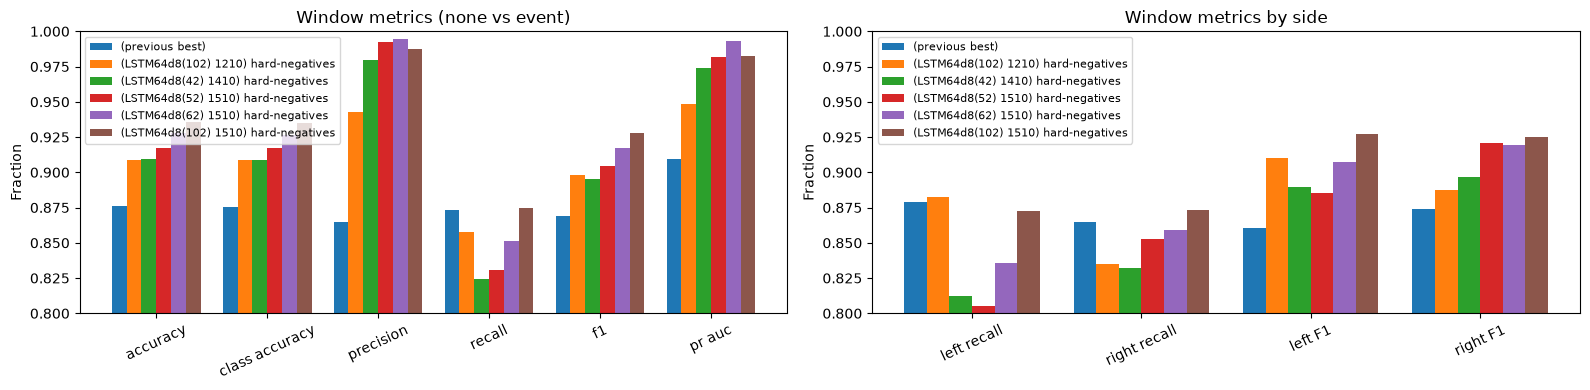

In [3]:
def grouped_bars(ax, table, columns, title, *, scale=1, ylabel='Score'):
    x = np.arange(len(columns))
    width = .8 / len(table)
    for i, (_, row) in enumerate(table.iterrows()):
        values = [row[column] * scale for column in columns]
        ax.bar(x - .4 + width*(i+.5), values, width, label=row['model'])
    ax.set(xticks=x, xticklabels=[name.replace('_', ' ') for name in columns],
           title=title, ylabel=ylabel)
    ax.tick_params(axis='x', rotation=25)
    ax.legend(fontsize=8)

window_metrics = scores[scores.level == 'window'].copy()
overall = window_metrics[window_metrics.side == 'all']
by_side = window_metrics[window_metrics.side != 'all'].copy()
by_side['side_recall'] = by_side.side + ' recall'
by_side['side_f1'] = by_side.side + ' F1'
per_side = pd.concat([
    by_side.pivot(index='model', columns='side_recall', values='recall'),
    by_side.pivot(index='model', columns='side_f1', values='f1')], axis=1).reindex(RUNS).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
grouped_bars(axes[0], overall, ['accuracy', 'class_accuracy', 'precision', 'recall', 'f1', 'pr_auc'],
             'Window metrics (none vs event)', ylabel='Fraction')
grouped_bars(axes[1], per_side, [c for c in per_side if c != 'model'],
             'Window metrics by side', ylabel='Fraction')
for ax in axes: ax.set_ylim(0.80, 1)
plt.tight_layout()
plt.show()

In [4]:
window_metrics[['model', 'side', 'left_threshold', 'right_threshold', 'n_samples',
                'tp', 'fp', 'fn', 'tn', 'accuracy', 'class_accuracy', 'precision',
                'recall', 'f1', 'pr_auc', 'roc_auc']]  # Full table: window_metrics.

,model,side,left_threshold,right_threshold,n_samples,tp,fp,fn,tn,accuracy,class_accuracy,precision,recall,f1,pr_auc,roc_auc
0,(previous best),all,0.80,0.75,1358.0,557,87,81,633.0,0.876289,0.875552,0.864907,0.873041,0.868955,0.909643,0.938438
1,(previous best),left,0.80,0.75,1358.0,262,49,36,1011.0,0.937408,NaN,0.842444,0.879195,0.860427,0.881985,0.970723
2,(previous best),right,0.80,0.75,1358.0,294,39,46,979.0,0.937408,NaN,0.882883,0.864706,0.873700,0.926000,0.980414
9,(LSTM64d8(102) 1210) hard-negatives,all,0.80,0.80,1358.0,547,33,91,687.0,0.908689,0.908689,0.943103,0.857367,0.898194,0.948800,0.962065
10,(LSTM64d8(102) 1210) hard-negatives,left,0.80,0.80,1358.0,263,17,35,1043.0,0.961708,NaN,0.939286,0.882550,0.910035,0.933558,0.983798
11,(LSTM64d8(102) 1210) hard-negatives,right,0.80,0.80,1358.0,284,16,56,1002.0,0.946981,NaN,0.946667,0.835294,0.887500,0.955755,0.984829
18,(LSTM64d8(42) 1410) hard-negatives,all,0.80,0.75,1358.0,526,11,112,709.0,0.909426,0.908689,0.979516,0.824451,0.895319,0.974226,0.978877
19,(LSTM64d8(42) 1410) hard-negatives,left,0.80,0.75,1358.0,242,4,56,1056.0,0.955817,NaN,0.983740,0.812081,0.889706,0.967755,0.989499
20,(LSTM64d8(42) 1410) hard-negatives,right,0.80,0.75,1358.0,283,8,57,1010.0,0.952135,NaN,0.972509,0.832353,0.896989,0.973210,0.991139
27,(LSTM64d8(52) 1510) hard-negatives,all,0.85,0.80,1358.0,530,4,108,716.0,0.917526,0.917526,0.992509,0.830721,0.904437,0.981568,0.985793


## Frame diagnostics
These per-frame values depend on the selected thresholds, except PR-AUC/ROC-AUC. Frames near the same physical event are correlated; streaming event results below are the primary product metrics.

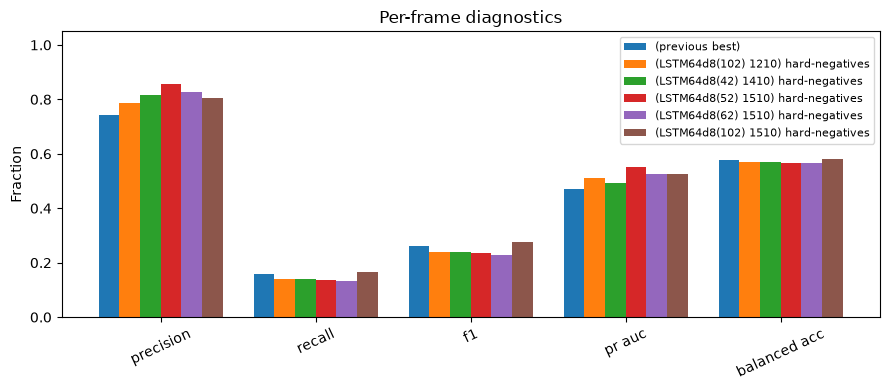

In [5]:
frame_metrics = scores[scores.level == 'frame'].copy()
fig, ax = plt.subplots(figsize=(9, 4))
grouped_bars(ax, frame_metrics[frame_metrics.side == 'all'],
             ['precision', 'recall', 'f1', 'pr_auc', 'balanced_acc'],
             'Per-frame diagnostics', ylabel='Fraction')
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [6]:
frame_metrics[frame_metrics['side'] == 'all'][['model', 'side', 'precision', 'recall', 'f1', 'pr_auc', 'roc_auc',
               'n_samples', 'tp', 'fp', 'fn']]  # Full table: frame_metrics.

,model,side,precision,recall,f1,pr_auc,roc_auc,n_samples,tp,fp,fn
3,(previous best),all,0.744145,0.158904,0.261886,0.471067,0.937214,411433.0,2129,732,11269
12,(LSTM64d8(102) 1210) hard-negatives,all,0.785892,0.141364,0.239626,0.510638,0.943511,411433.0,1894,516,11504
21,(LSTM64d8(42) 1410) hard-negatives,all,0.816107,0.141439,0.241094,0.493733,0.931444,411433.0,1895,427,11503
30,(LSTM64d8(52) 1510) hard-negatives,all,0.857547,0.135692,0.234309,0.550892,0.942283,411433.0,1818,302,11580
39,(LSTM64d8(62) 1510) hard-negatives,all,0.826291,0.131363,0.226687,0.526890,0.938523,411433.0,1760,370,11638
48,(LSTM64d8(102) 1510) hard-negatives,all,0.803261,0.165472,0.274415,0.526832,0.950549,411433.0,2217,543,11181


## Streaming event detection
Event matching is class-aware, one-to-one, and uses the **actual alarm-emission frame**. FP/min counts unmatched alarms over validation exposure minutes, including early and wrong-side alarms. For `negative_mining` crops, the denominator uses each hash-verified original recording's actual length **once per unique source**, allocated across its evaluated crops; ordinary files retain evaluated duration. `recording_duration_audit` shows the source lengths and allocations; `evaluated_minutes` retains input length. Older exports' displayed rates are recalculated without changing their alarm counts or saved thresholds. Rerun `evaluate.ipynb` to reselect thresholds with the new denominator. **Crop alarms / full source minutes is not a measured full-source or normal-use FP rate.** The selected operating point can differ per model even though its selection mode is the same.

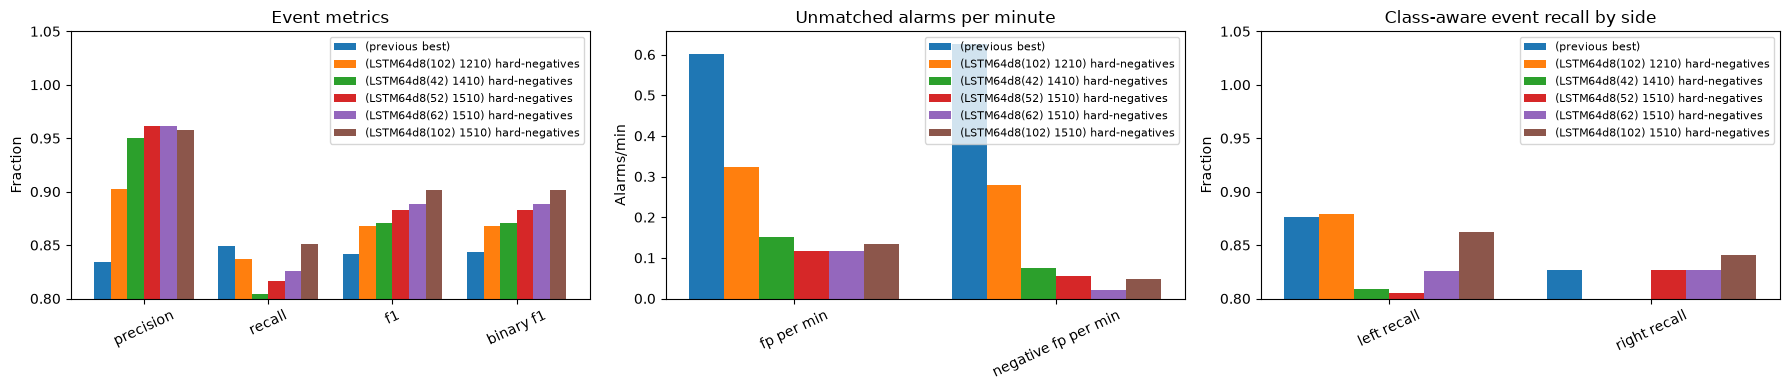

In [7]:
event_metrics = scores[scores.level == 'event'].copy()
event_overall = event_metrics[event_metrics.side == 'all']
event_side = event_metrics[event_metrics.side != 'all'].copy()
event_side['side_recall'] = event_side.side + ' recall'
side_recall = event_side.pivot(index='model', columns='side_recall', values='recall').reindex(RUNS).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
grouped_bars(axes[0], event_overall, ['precision', 'recall', 'f1', 'binary_f1'],
             'Event metrics', ylabel='Fraction')
grouped_bars(axes[1], event_overall, ['fp_per_min', 'negative_fp_per_min'],
             'Unmatched alarms per minute', ylabel='Alarms/min')
grouped_bars(axes[2], side_recall, [c for c in side_recall if c != 'model'],
             'Class-aware event recall by side', ylabel='Fraction')
axes[0].set_ylim(0.8, 1.05)
axes[2].set_ylim(0.8, 1.05)
plt.tight_layout()
plt.show()

In [8]:
event_metrics[event_metrics['side'] == 'all'][['model', 'side', 'tp', 'fp', 'fn', 'precision', 'recall', 'f1',
               'binary_f1', 'fp_per_min', 'negative_fp_per_min',
               'left_threshold', 'right_threshold']]  # Full table: event_metrics.

,model,side,tp,fp,fn,precision,recall,f1,binary_f1,fp_per_min,negative_fp_per_min,left_threshold,right_threshold
6,(previous best),all,542,108,96,0.833846,0.849530,0.841615,0.843168,0.602195,0.625704,0.80,0.75
15,(LSTM64d8(102) 1210) hard-negatives,all,534,58,104,0.902027,0.836991,0.868293,0.868293,0.323401,0.278846,0.80,0.80
24,(LSTM64d8(42) 1410) hard-negatives,all,513,27,125,0.950000,0.804075,0.870968,0.870968,0.150549,0.074812,0.80,0.75
33,(LSTM64d8(52) 1510) hard-negatives,all,521,21,117,0.961255,0.816614,0.883051,0.883051,0.117094,0.054409,0.85,0.80
42,(LSTM64d8(62) 1510) hard-negatives,all,527,21,111,0.961679,0.826019,0.888702,0.888702,0.117094,0.020403,0.80,0.80
51,(LSTM64d8(102) 1510) hard-negatives,all,543,24,95,0.957672,0.851097,0.901245,0.901245,0.133821,0.047608,0.80,0.75


## Measured FP rate on full normal_usage originals
This section replays every selected checkpoint at its **frozen exported thresholds** over every frame of the original `normal_usage` CSVs, with state/cooldown continuous across source sessions and reset only between files. No crops are added to this rate. `NORMAL_USAGE_FILES=None` selects all originals in `NORMAL_USAGE_SOURCE_DIR`; use a list for a consistent held-out population, or `[]` to disable. Identical source copies count once per model. Zero-alarm recordings still contribute their full duration. If crops from these originals were used in training/tuning, results are descriptive, not independent test estimates. New evaluation exports include this population's hashes; older exports can still be replayed without retuning.


,file,source_sha256,frames,sample_rate_hz,minutes
0,imu_Miguel_normal_usage_20261013_173950.csv,8aa5e9b1d76a0e0d50fc9a895f1425aef61b43d3b4fa64...,25276,100.0,4.212667
1,imu_Miguel_normal_usage_20261013_175122.csv,2bbd34fb44986ca41fd7d0c362b7ecd418e5510d165bc2...,23857,100.0,3.976167
2,imu_Miguel_normal_usage_20261013_181009.csv,cd914502048e03b600e74f1c420477b74fc5bd31aadb25...,29999,100.0,4.999833
3,imu_Miguel_normal_usage_20261013_181906.csv,25a843e4683f3254c787d6d3a7a5162e03b2110d568fd0...,30000,100.0,5.000000
4,imu_Miguel_normal_usage_20261013_185932.csv,9369d4b19eaf87977d0a89d061e9b4d6c13129131f280a...,30002,100.0,5.000333
5,imu_Miguel_normal_usage_20261013_190252.csv,361f9006662396c8d981e7499ce95d9e1259651342b310...,1942,100.0,0.323667
6,imu_Miguel_normal_usage_20261013_191149.csv,36d5df9bf929dcb519a254740a5c90f9c114ce101ce2bb...,30000,100.0,5.000000
7,imu_Miguel_normal_usage_20261013_192249.csv,79d93b5394ad35416ea8aec2436bd5454fb43a0c6debbc...,30002,100.0,5.000333
8,imu_Miguel_normal_usage_20261013_192551.csv,61be98833c4af07a441083ed2d42e2fd3d09a38a5757de...,14508,100.0,2.418000
9,imu_Miguel_normal_usage_20261013_192806.csv,49585b129aff593aa55e3bd64be2066cddf71c67b1a83b...,4806,100.0,0.801000


,model,selection_mode,policy,left_threshold,right_threshold,normal_usage_sha256,normal_usage_recordings,normal_usage_minutes,normal_usage_fp,normal_usage_fp_per_min
0,(previous best),recall_target_max_threshold,lookahead_12f,0.80,0.75,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...,55,213.578333,113,0.529080
1,(LSTM64d8(102) 1210) hard-negatives,recall_target_max_threshold,lookahead_12f,0.80,0.80,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...,55,213.578333,132,0.618040
2,(LSTM64d8(42) 1410) hard-negatives,recall_target_max_threshold,lookahead_12f,0.80,0.75,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...,55,213.578333,16,0.074914
3,(LSTM64d8(52) 1510) hard-negatives,recall_target_max_threshold,lookahead_12f,0.85,0.80,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...,55,213.578333,9,0.042139
4,(LSTM64d8(62) 1510) hard-negatives,recall_target_max_threshold,lookahead_12f,0.80,0.80,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...,55,213.578333,3,0.014046
5,(LSTM64d8(102) 1510) hard-negatives,recall_target_max_threshold,lookahead_12f,0.80,0.75,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...,55,213.578333,17,0.079596


,file,recording_type,source_sha256,minutes,frames,event_fp,event_left_fp,event_right_fp,event_fp_per_min,model,selection_mode,policy,left_threshold,right_threshold,normal_usage_sha256
108,imu_Miguel_normal_usage_20261015_093708.csv,normal_usage,6179cf43a92a276f9cfe724b4b04669cb139aa53908602...,4.714333,28286,24,6,18,5.090858,(LSTM64d8(102) 1210) hard-negatives,recall_target_max_threshold,lookahead_12f,0.8,0.80,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
103,imu_Miguel_normal_usage_20261014_191054.csv,normal_usage,620df9d61d37027a908a91cd0f0bf997196aa454e69613...,5.000000,30000,21,1,20,4.200000,(LSTM64d8(102) 1210) hard-negatives,recall_target_max_threshold,lookahead_12f,0.8,0.80,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
107,imu_Miguel_normal_usage_20261015_093218.csv,normal_usage,4cab8e08ea1b8e9687db8c5e52a70c2302aa79b13be2eb...,5.000167,30001,17,1,16,3.399887,(LSTM64d8(102) 1210) hard-negatives,recall_target_max_threshold,lookahead_12f,0.8,0.80,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
70,imu_Miguel_normal_usage_20261014_091755.csv,normal_usage,acf18622e87146878c206e2dac7475799683ed1a3bfb90...,5.000000,30000,11,0,11,2.200000,(LSTM64d8(102) 1210) hard-negatives,recall_target_max_threshold,lookahead_12f,0.8,0.80,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
85,imu_Miguel_normal_usage_20261014_131245.csv,normal_usage,0600686f2c040e5fdc65fc85fbf4be91da5276cebddd4d...,2.442833,14657,4,0,4,1.637443,(LSTM64d8(102) 1210) hard-negatives,recall_target_max_threshold,lookahead_12f,0.8,0.80,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42,imu_Miguel_normal_usage_20261014_180025.csv,normal_usage,94158c12d0b2bbdc8e99c1fd83119cea200ce0c4cf2c05...,4.999833,29999,0,0,0,0.000000,(previous best),recall_target_max_threshold,lookahead_12f,0.8,0.75,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
44,imu_Miguel_normal_usage_20261014_181245.csv,normal_usage,e53817d45e8e106f992f0acbfea3e5e7cc409b9c56bee3...,4.193167,25159,0,0,0,0.000000,(previous best),recall_target_max_threshold,lookahead_12f,0.8,0.75,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
46,imu_Miguel_normal_usage_20261014_185638.csv,normal_usage,5d9e400d6e03bdd48ad54eb3a28dff052791882c85de69...,3.692500,22155,0,0,0,0.000000,(previous best),recall_target_max_threshold,lookahead_12f,0.8,0.75,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...
47,imu_Miguel_normal_usage_20261014_190116.csv,normal_usage,9d2daba8dfc9d1eb475ca4cc39f2254a2aacaadb1b6728...,0.491167,2947,0,0,0,0.000000,(previous best),recall_target_max_threshold,lookahead_12f,0.8,0.75,29e1ed7cbde618557628af99818fed64d3c7de8d800fe4...


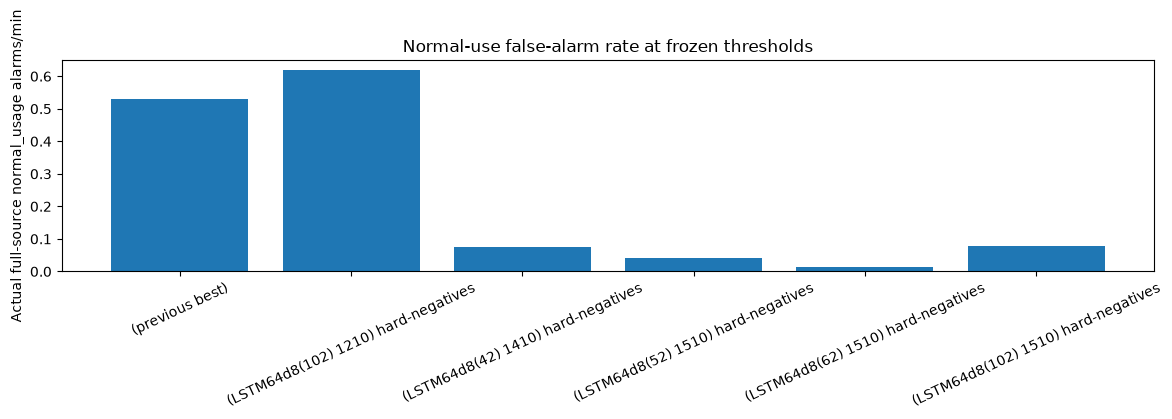

In [9]:
normal_usage_points = operating_points.merge(comparison_sources[[
    'model', 'checkpoint_path', 'evaluation_data', 'normal_usage_export_sha256']],
    on='model', validate='one_to_one')
normal_usage_scores, normal_usage_file_scores, normal_usage_alarm_details, normal_usage_manifest, normal_usage_sha256 = (
    replay_normal_usage(ROOT, normal_usage_points, NORMAL_USAGE_SOURCE_DIR,
                        NORMAL_USAGE_FILES, NORMAL_USAGE_CHUNK_FRAMES))
display(normal_usage_manifest)
if normal_usage_scores.empty:
    print('No normal_usage originals selected. Place full CSVs in', NORMAL_USAGE_SOURCE_DIR,
          'or edit NORMAL_USAGE_FILES; crops are never used for this metric.')
else:
    for row in normal_usage_points.itertuples(index=False):
        if row.normal_usage_export_sha256 != normal_usage_sha256:
            print(row.model, ': current full-normal-use population differs from or is absent '
                  'in its export. Thresholds remain frozen; rerun evaluation to tune on this population.')
    display(normal_usage_scores)
    display(normal_usage_file_scores.sort_values(['model', 'event_fp_per_min'], ascending=[True, False]))
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(normal_usage_scores.model, normal_usage_scores.normal_usage_fp_per_min)
    ax.set(ylabel='Actual full-source normal_usage alarms/min', title='Normal-use false-alarm rate at frozen thresholds')
    ax.tick_params(axis='x', rotation=25)
    plt.tight_layout()
    plt.show()


## Alarm latency
Deadline recall is the fraction of **all annotated events** detected before X frames (misses remain in the denominator). Mean/median/p90 latency includes matched events only and can be misleading if recall is low.

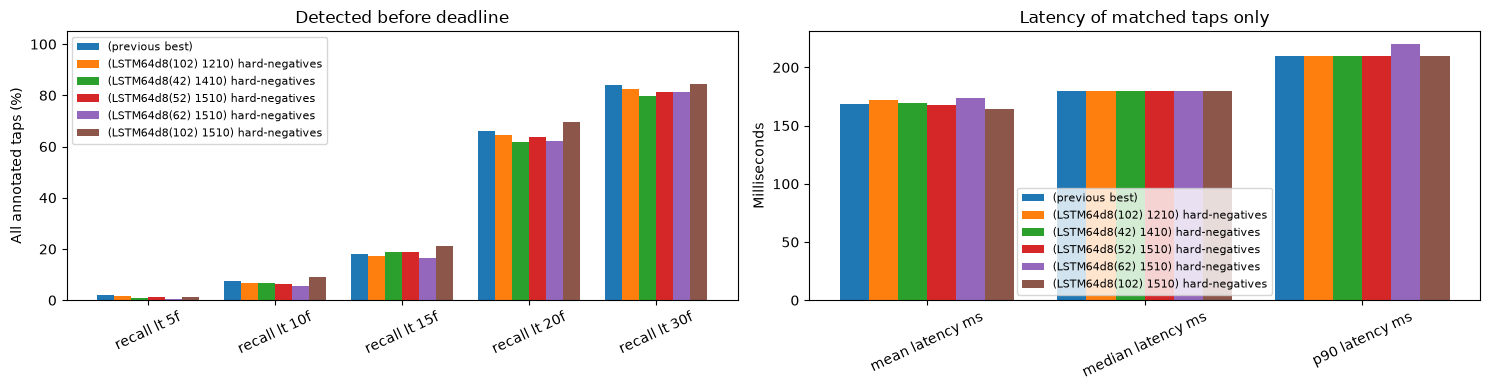

In [10]:
latency_metrics = event_overall[['model', 'left_threshold', 'right_threshold',
                                 'recall_lt_5f', 'recall_lt_10f', 'recall_lt_15f',
                                 'recall_lt_20f', 'recall_lt_30f', 'mean_latency_ms',
                                 'median_latency_ms', 'p90_latency_ms', 'tp', 'fn']].copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
grouped_bars(axes[0], latency_metrics,
             ['recall_lt_5f', 'recall_lt_10f', 'recall_lt_15f', 'recall_lt_20f', 'recall_lt_30f'],
             'Detected before deadline', scale=100, ylabel='All annotated taps (%)')
grouped_bars(axes[1], latency_metrics,
             ['mean_latency_ms', 'median_latency_ms', 'p90_latency_ms'],
             'Latency of matched taps only', ylabel='Milliseconds')
axes[0].set_ylim(0, 105)
plt.tight_layout()
plt.show()

## Recording types and individual files
Rows use the same selected policy and left/right thresholds as the event and window plots. Negative-only types have undefined event recall; their FP/min and false-positive window rates are the useful metrics. `switch_doubletap` is a separate standard negative activity (20 × 3-second sections, normal timing), not `knock_twice` or `hard_negative`. With an empty label `.txt`, all of its windows are `none` and all alarms are false positives. It appears automatically in the negative-type plots and tables once each run is evaluated on the same dataset containing those recordings and its exports are regenerated. Grouped by type, every value is pooled over its files (not an average of file percentages). Some types contain only one file.

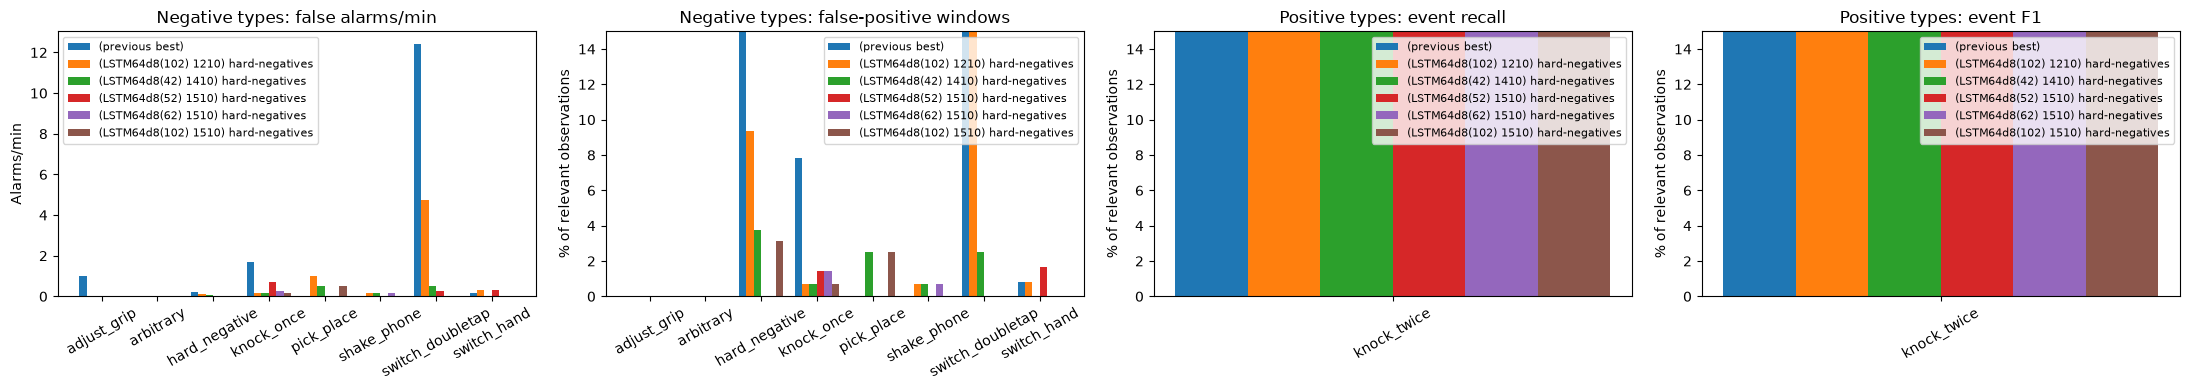

In [11]:
type_comparison = type_scores.copy()
switch_doubletap_rows = type_comparison[type_comparison.recording_type == 'switch_doubletap']
assert switch_doubletap_rows.n_true_events.eq(0).all(), 'switch_doubletap exports must contain no positive events'
negative = type_comparison[type_comparison.n_true_events == 0]
positive = type_comparison[type_comparison.n_true_events > 0]
fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for ax, subset, metric, title, scale in [
        (axes[0], negative, 'event_fp_per_min', 'Negative types: false alarms/min', 1),
        (axes[1], negative, 'window_false_positive_rate', 'Negative types: false-positive windows', 100),
        (axes[2], positive, 'event_recall', 'Positive types: event recall', 100),
        (axes[3], positive, 'event_f1', 'Positive types: event F1', 100)]:
    x = sorted(subset.recording_type.unique())
    width = .8 / len(RUNS)
    for i, label in enumerate(RUNS):
        rows = subset[subset.model == label].set_index('recording_type').reindex(x)
        ax.bar(np.arange(len(x)) - .4 + width*(i+.5), rows[metric] * scale, width, label=label)
    ax.set(xticks=np.arange(len(x)), xticklabels=x, title=title)
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Alarms/min')
for ax in axes[1:]: ax.set(ylabel='% of relevant observations', ylim=(0, 15))
plt.tight_layout()
plt.show()

In [12]:
type_comparison[['model', 'recording_type', 'recordings', 'n_windows', 'n_true_events',
                 'event_tp', 'event_fp', 'event_fn', 'event_f1', 'event_fp_per_min',
                 'event_left_recall', 'event_right_recall', 'window_accuracy',
                 'window_false_positive_rate']]  # Full table: type_comparison.

,model,recording_type,recordings,n_windows,n_true_events,event_tp,event_fp,event_fn,event_f1,event_fp_per_min,event_left_recall,event_right_recall,window_accuracy,window_false_positive_rate
0,(previous best),adjust_grip,1,20,0,0,1,0,0.000000,0.989936,NaN,NaN,1.000000,0.000000
1,(previous best),arbitrary,1,20,0,0,0,0,NaN,0.000000,NaN,NaN,1.000000,0.000000
2,(previous best),hard_negative,160,160,0,0,28,0,0.000000,0.235746,NaN,NaN,0.831250,0.168750
3,(previous best),knock_once,7,140,0,0,12,0,0.000000,1.697913,NaN,NaN,0.921429,0.078571
4,(previous best),knock_twice,32,638,638,542,16,96,0.906355,0.495210,0.875839,0.826471,0.871473,NaN
5,(previous best),pick_place,2,40,0,0,0,0,NaN,0.000000,NaN,NaN,1.000000,0.000000
6,(previous best),shake_phone,7,140,0,0,0,0,NaN,0.000000,NaN,NaN,1.000000,0.000000
7,(previous best),switch_doubletap,4,80,0,0,50,0,0.000000,12.418761,NaN,NaN,0.400000,0.600000
8,(previous best),switch_hand,6,120,0,0,1,0,0.000000,0.165044,NaN,NaN,0.991667,0.008333
9,(LSTM64d8(102) 1210) hard-negatives,adjust_grip,1,20,0,0,0,0,NaN,0.000000,NaN,NaN,1.000000,0.000000


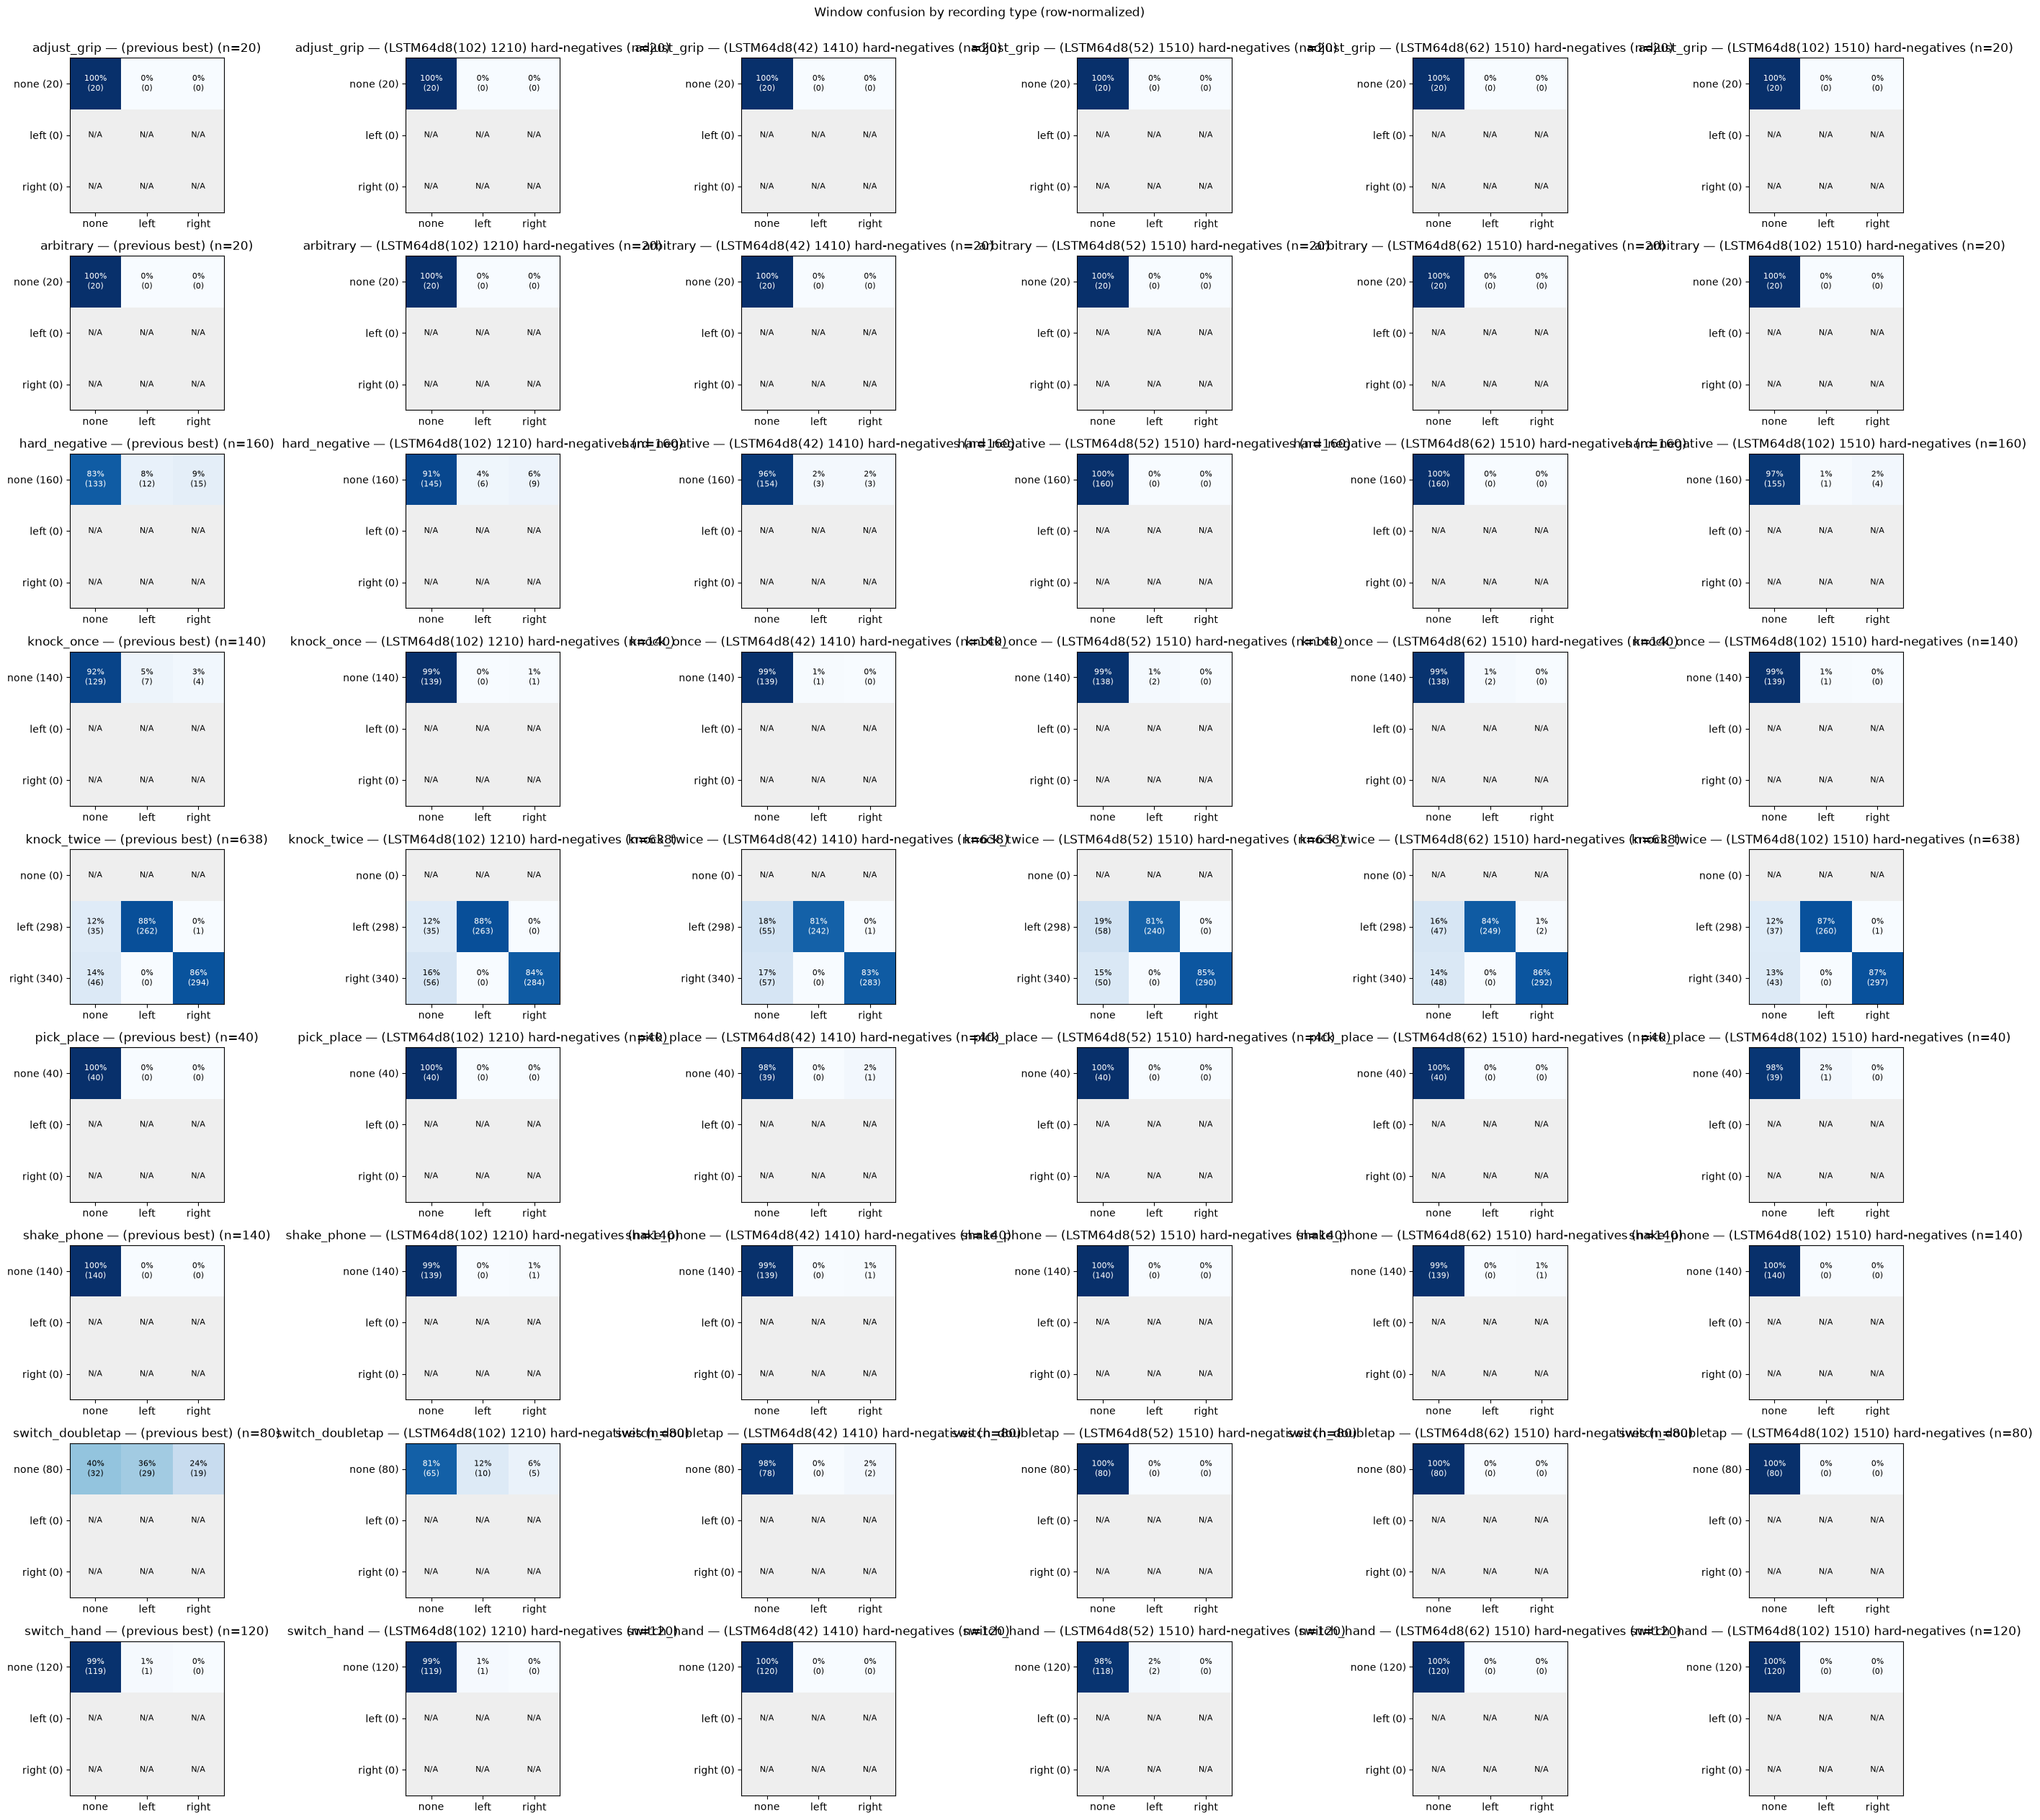

In [13]:
from matplotlib.colors import Normalize
confusion_rows = []
recording_types = sorted(expected_types)
fig, axes = plt.subplots(len(recording_types), len(RUNS),
                         figsize=(4.8*len(RUNS), 2.8*len(recording_types)), squeeze=False)
colors = plt.get_cmap('Blues').copy()
colors.set_bad('#eeeeee')
for i, recording_type in enumerate(recording_types):
    for j, model_name in enumerate(RUNS):
        row = type_comparison[(type_comparison.recording_type == recording_type) &
                              (type_comparison.model == model_name)].iloc[0]
        cm = np.array([[int(row[f'cm_{t}{p}']) for p in range(3)] for t in range(3)])
        totals = cm.sum(axis=1)
        fractions = np.divide(cm, totals[:, None], out=np.full((3, 3), np.nan),
                              where=totals[:, None] > 0)
        ax = axes[i, j]
        ax.imshow(np.ma.masked_invalid(fractions), cmap=colors, norm=Normalize(0, 1))
        ax.set(title=f'{recording_type} — {model_name} (n={cm.sum()})',
               xticks=range(3), xticklabels=('none', 'left', 'right'),
               yticks=range(3), yticklabels=[f'{name} ({n})' for name, n in
                                        zip(('none', 'left', 'right'), totals)])
        for t, true_class in enumerate(('none', 'left', 'right')):
            for p, predicted_class in enumerate(('none', 'left', 'right')):
                ax.text(p, t, f'{fractions[t, p]:.0%}\n({cm[t, p]})' if totals[t] else 'N/A',
                        ha='center', va='center', fontsize=8,
                        color='white' if totals[t] and fractions[t, p] > .55 else 'black')
                confusion_rows.append(dict(model=model_name, recording_type=recording_type,
                                           true_class=true_class, predicted_class=predicted_class,
                                           count=int(cm[t, p]), true_count=int(totals[t]),
                                           row_fraction=fractions[t, p]))
fig.suptitle('Window confusion by recording type (row-normalized)', y=1.001)
plt.tight_layout()
plt.show()
type_confusion_comparison = pd.DataFrame(confusion_rows)

In [14]:
type_confusion_comparison  # N/A rows have no observed examples of that true class.

,model,recording_type,true_class,predicted_class,count,true_count,row_fraction
0,(previous best),adjust_grip,none,none,20,20,1.0
1,(previous best),adjust_grip,none,left,0,20,0.0
2,(previous best),adjust_grip,none,right,0,20,0.0
3,(previous best),adjust_grip,left,none,0,0,NaN
4,(previous best),adjust_grip,left,left,0,0,NaN
...,...,...,...,...,...,...,...
481,(LSTM64d8(102) 1510) hard-negatives,switch_hand,left,left,0,0,NaN
482,(LSTM64d8(102) 1510) hard-negatives,switch_hand,left,right,0,0,NaN
483,(LSTM64d8(102) 1510) hard-negatives,switch_hand,right,none,0,0,NaN
484,(LSTM64d8(102) 1510) hard-negatives,switch_hand,right,left,0,0,NaN




In [15]:
recording_comparison = file_scores.copy()
files = sorted(recording_comparison.file.unique())
fig, axes = plt.subplots(1, 2, figsize=(14, max(6, .55*len(files))))
for ax, field, label, cmap in [
        (axes[0], 'event_fp_per_min', 'Unmatched alarms/min', 'Oranges'),
        (axes[1], 'window_accuracy', 'Window accuracy', 'Blues')]:
    table = recording_comparison.pivot(index='file', columns='model', values=field).reindex(
        index=files, columns=list(RUNS))
    data = table.to_numpy(dtype=float)
    im = ax.imshow(data, aspect='auto', cmap=cmap, vmin=0, vmax=1 if field == 'window_accuracy' else None)
    ax.set(yticks=np.arange(len(files)), yticklabels=files, xticks=np.arange(len(RUNS)),
           xticklabels=list(RUNS), title=label)
    ax.tick_params(axis='x', rotation=20)
    for i in range(len(files)):
        for j in range(len(RUNS)):
            ax.text(j, i, f'{data[i, j]:.2f}',
                    ha='center', va='center', color='black', fontsize=8)
    fig.colorbar(im, ax=ax, fraction=.04, pad=.02)
plt.tight_layout()
plt.show()

In [16]:
recording_comparison[['model', 'file', 'recording_type', 'n_windows',
                      'n_true_events', 'event_tp', 'event_fp', 'event_fn',
                      'window_fp', 'window_fn', 'event_fp_per_min', 'minutes']]  # Full table: recording_comparison.

,model,file,recording_type,n_windows,n_true_events,event_tp,event_fp,event_fn,window_fp,window_fn,event_fp_per_min,minutes
0,(previous best),imuStrict_Miguel_knock_twice_left_20260929_115...,knock_twice,20,20,20,0,0,0,0,0.000000,1.010500
1,(previous best),imuStrict_Miguel_knock_twice_left_20260929_153...,knock_twice,20,20,19,0,1,0,1,0.000000,1.010167
2,(previous best),imuStrict_Miguel_knock_twice_left_20260929_153...,knock_twice,20,20,20,0,0,0,0,0.000000,1.010667
3,(previous best),imuStrict_Miguel_knock_twice_left_20260930_150...,knock_twice,20,20,19,0,1,0,1,0.000000,1.010500
4,(previous best),imuStrict_Miguel_knock_twice_left_20260930_150...,knock_twice,20,20,17,0,3,0,3,0.000000,1.009667
...,...,...,...,...,...,...,...,...,...,...,...,...
1315,(LSTM64d8(102) 1510) hard-negatives,imu_ZR_pick_place_20260909_091335.csv,pick_place,20,0,0,1,0,1,0,0.989772,1.010333
1316,(LSTM64d8(102) 1510) hard-negatives,imu_ZR_shake_phone_20260904_102826.csv,shake_phone,20,0,0,0,0,0,0,0.000000,1.008833
1317,(LSTM64d8(102) 1510) hard-negatives,imu_ZR_shake_phone_20260908_175719.csv,shake_phone,20,0,0,0,0,0,0,0.000000,1.009000
1318,(LSTM64d8(102) 1510) hard-negatives,imu_ZR_shake_phone_20260909_091204.csv,shake_phone,20,0,0,0,0,0,0,0.000000,1.010667


## Inspect individual validation examples (current recordings)
The saved exports above contain per-recording totals, but not individual segment predictions or probability traces. The next cell replays each selected `best.pt` on **the current validation files** at its saved left/right thresholds, with the same window fitting, continuous causal inference, class-aware event matching, and alarm policy as the evaluator. Alarm emission times are matched inclusively in `[-MATCH_EARLY_FRAMES, +MATCH_LATE_FRAMES]` around the annotated second tap (default: `[-25, +40]` frames). The same interval applies to the training replay below. It does not tune thresholds. Full `negative_mining` recordings and their mined crop files are reported as `hard_negative` in detailed replay tables. `example_data_status` shows whether today's raw CSVs, label text files, and exclusion registry still match the original exports. Detailed replay totals can differ from historical exported totals when the data or matching interval differs.

`segment_scores` and `recording_scores` are long-form filterable tables; `segment_matrix` and `recording_matrix` put each model in its own column group. Segment IDs are the CSV's `segment_index` (not window row numbers). Event TP/FP/FN use one-to-one matching on the **whole recording** before attribution to a segment; `too_early_fp` counts unmatched alarms emitted too early for their nearest tap, while `wrong_side_fp` is an unmatched alarm that matched in the side-agnostic check. Window classification is separate from alarm matching. Excluded segments and unlabeled windows are not scored.


In [17]:
import importlib
import sys
sys.path.insert(0, str(ROOT))
import torch
from notebooks_analysis import model_comparison_examples

# Reload so rerunning this cell uses the current replay implementation.
importlib.reload(model_comparison_examples)
comparison_matrix = model_comparison_examples.comparison_matrix
plot_example = model_comparison_examples.plot_example
replay_examples = model_comparison_examples.replay_examples

torch.set_num_threads(2)
detail_points = operating_points.merge(comparison_sources[[
    'model', 'folder', 'checkpoint_path', 'evaluation_data',
    'evaluation_labels', 'evaluation_seed',
]],
                                       on='model', validate='one_to_one')
detail_points['early_allowance_frames'] = MATCH_EARLY_FRAMES
detail_points['max_late_frames'] = MATCH_LATE_FRAMES
print(f'Replay matching interval: [-{MATCH_EARLY_FRAMES}, +{MATCH_LATE_FRAMES}] frames around the second tap (inclusive)')
example_recordings, example_traces, segment_scores, recording_scores, alarm_details, example_data_status = (
    replay_examples(ROOT, detail_points, source_dir=MINING_SOURCE_DIR)
)
display(example_data_status)
print('Detailed replay:', len(segment_scores), 'model/segment rows,',
      len(recording_scores), 'model/recording rows,', len(alarm_details), 'alarms')

Replay matching interval: [-25, +40] frames around the second tap (inclusive)


,model,split,export_validation_sha256,current_validation_sha256,matches_export
0,(previous best),valid,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,True
1,(LSTM64d8(102) 1210) hard-negatives,valid,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,True
2,(LSTM64d8(42) 1410) hard-negatives,valid,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,True
3,(LSTM64d8(52) 1510) hard-negatives,valid,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,True
4,(LSTM64d8(62) 1510) hard-negatives,valid,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,True
5,(LSTM64d8(102) 1510) hard-negatives,valid,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,fb9011f2d6e99e2eff4b115148b410cb341de2f46473fa...,True


Detailed replay: 8160 model/segment rows, 1320 model/recording rows, 3439 alarms


### Find difficult segments and recordings
Filter `segment_scores.query("recording_type == 'knock_twice' and event_fn > 0")` for missed double taps or `segment_scores.query('too_early_fp > 0 or wrong_side_fp > 0')` for premature/wrong-side alarms. `alarm_details` gives each alarm's global emission/peak frame, closest annotation, matched status, and segment ID. `recording_scores` includes both knock-twice recordings and negative-only activity; its `event_fp_per_min` uses allocated original-source minutes for mined crops and included segment minutes for other files. Segments divide each file's allocation proportionally to included duration. `evaluated_minutes` retains actual input durations. Source exposure is counted once per split and model, never summed across model aliases. Edit the displayed slices or filter `segment_matrix.loc[('filename.csv', 8)]` / `recording_matrix.loc['filename.csv']` to see every model together.


In [18]:

    

segment_matrix = comparison_matrix(segment_scores, ['file', 'segment_index'],
    ['window_true', 'window_pred', 'window_correct', 'window_fp', 'window_fn',
     'p_left_max', 'p_right_max', 'event_tp', 'event_fp', 'event_fn',
     'too_early_fp', 'wrong_side_fp', 'latency_frames'])
recording_matrix = comparison_matrix(recording_scores, ['file'],
    ['recording_type', 'minutes', 'n_windows', 'window_accuracy', 'window_fp', 'window_fn',
     'n_true_events', 'event_tp', 'event_fp', 'event_fn', 'too_early_fp',
     'wrong_side_fp', 'event_fp_per_min'])
segment_difficulty = segment_scores.groupby(['file', 'segment_index', 'recording_type'],
    as_index=False).agg(models_missing=('event_fn', lambda x: (x > 0).sum()),
                        models_false_alarm=('event_fp', lambda x: (x > 0).sum()),
                        models_window_wrong=('window_correct', lambda x: (x == False).sum()),
                        too_early_fp=('too_early_fp', 'sum'), wrong_side_fp=('wrong_side_fp', 'sum'))
print('Hard double-tap segments (one row per CSV segment):')
with pd.option_context('display.max_colwidth', None):
    display(segment_difficulty.query("recording_type == 'knock_twice'")
        .sort_values(['models_missing', 'too_early_fp', 'models_false_alarm'],
                     ascending=False).head(25))
print('Hard recordings (one row per model/recording):')
with pd.option_context('display.max_colwidth', None):
    display(recording_scores.sort_values(['event_fp_per_min', 'event_fn'], ascending=False)
        [['model', 'file', 'recording_type', 'n_true_events', 'event_tp', 'event_fp',
          'event_fn', 'too_early_fp', 'window_fp', 'event_fp_per_min']].head(25))

Hard double-tap segments (one row per CSV segment):


,file,segment_index,recording_type,models_missing,models_false_alarm,models_window_wrong,too_early_fp,wrong_side_fp
767,imu_Miguel_knock_twice_right_20260925_152549.csv,8,knock_twice,6,1,5,1,0
209,imuStrict_Miguel_knock_twice_right_20260929_114726.csv,10,knock_twice,6,6,0,0,0
717,imu_Miguel_knock_twice_right_20260923_113004.csv,18,knock_twice,6,6,0,0,0
723,imu_Miguel_knock_twice_right_20260923_175649.csv,4,knock_twice,6,6,0,0,0
727,imu_Miguel_knock_twice_right_20260923_175649.csv,8,knock_twice,6,6,0,0,0
731,imu_Miguel_knock_twice_right_20260923_175649.csv,12,knock_twice,6,6,0,0,0
759,imu_Miguel_knock_twice_right_20260925_105253.csv,20,knock_twice,6,6,0,0,0
769,imu_Miguel_knock_twice_right_20260925_152549.csv,10,knock_twice,6,6,0,0,0
776,imu_Miguel_knock_twice_right_20260925_152549.csv,17,knock_twice,6,6,0,0,0
662,imu_Miguel_knock_twice_left_20260925_152423.csv,3,knock_twice,6,5,1,0,0


Hard recordings (one row per model/recording):


,model,file,recording_type,n_true_events,event_tp,event_fp,event_fn,too_early_fp,window_fp,event_fp_per_min
1154,(previous best),imu_Miguel_negative_mining_20261009_173341__crop_f004350_f004650.csv,hard_negative,0,0,1,0,0,1.0,14.002334
1156,(previous best),imu_Miguel_negative_mining_20261009_173341__crop_f004558_f004858.csv,hard_negative,0,0,1,0,0,1.0,14.002334
1157,(previous best),imu_Miguel_negative_mining_20261009_173341__crop_f004853_f005153.csv,hard_negative,0,0,1,0,0,1.0,14.002334
1158,(previous best),imu_Miguel_negative_mining_20261009_173341__crop_f004957_f005257.csv,hard_negative,0,0,1,0,0,1.0,14.002334
1160,(previous best),imu_Miguel_negative_mining_20261009_173341__crop_f005175_f005475.csv,hard_negative,0,0,1,0,0,1.0,14.002334
1162,(previous best),imu_Miguel_negative_mining_20261009_173341__crop_f005616_f005916.csv,hard_negative,0,0,1,0,0,1.0,14.002334
1305,(previous best),imu_Miguel_switch_doubletap_20261012_172856.csv,switch_doubletap,0,0,14,0,0,14.0,13.902681
1304,(previous best),imu_Miguel_switch_doubletap_20261012_172617.csv,switch_doubletap,0,0,12,0,0,11.0,11.938319
1307,(previous best),imu_Miguel_switch_doubletap_20261013_174125.csv,switch_doubletap,0,0,12,0,0,12.0,11.922504
1306,(previous best),imu_Miguel_switch_doubletap_20261012_173422.csv,switch_doubletap,0,0,12,0,0,11.0,11.910670


### Aligned recording/segment inspection
Choose a `file` and optionally a `segment_index` from the tables. The top row shows acceleration deviation and gyro magnitude from the original CSV; the following rows show each model's left/right probabilities, dotted operating thresholds, annotated second taps (dashed), and emitted alarms (triangles; red edges are unmatched alarms). All rows share the original recording's time axis. Use `REVIEW_SEGMENT = None` to inspect an entire recording.


,model,file,segment_index,window_true,window_pred,event_tp,event_fp,event_fn,too_early_fp,latency_frames


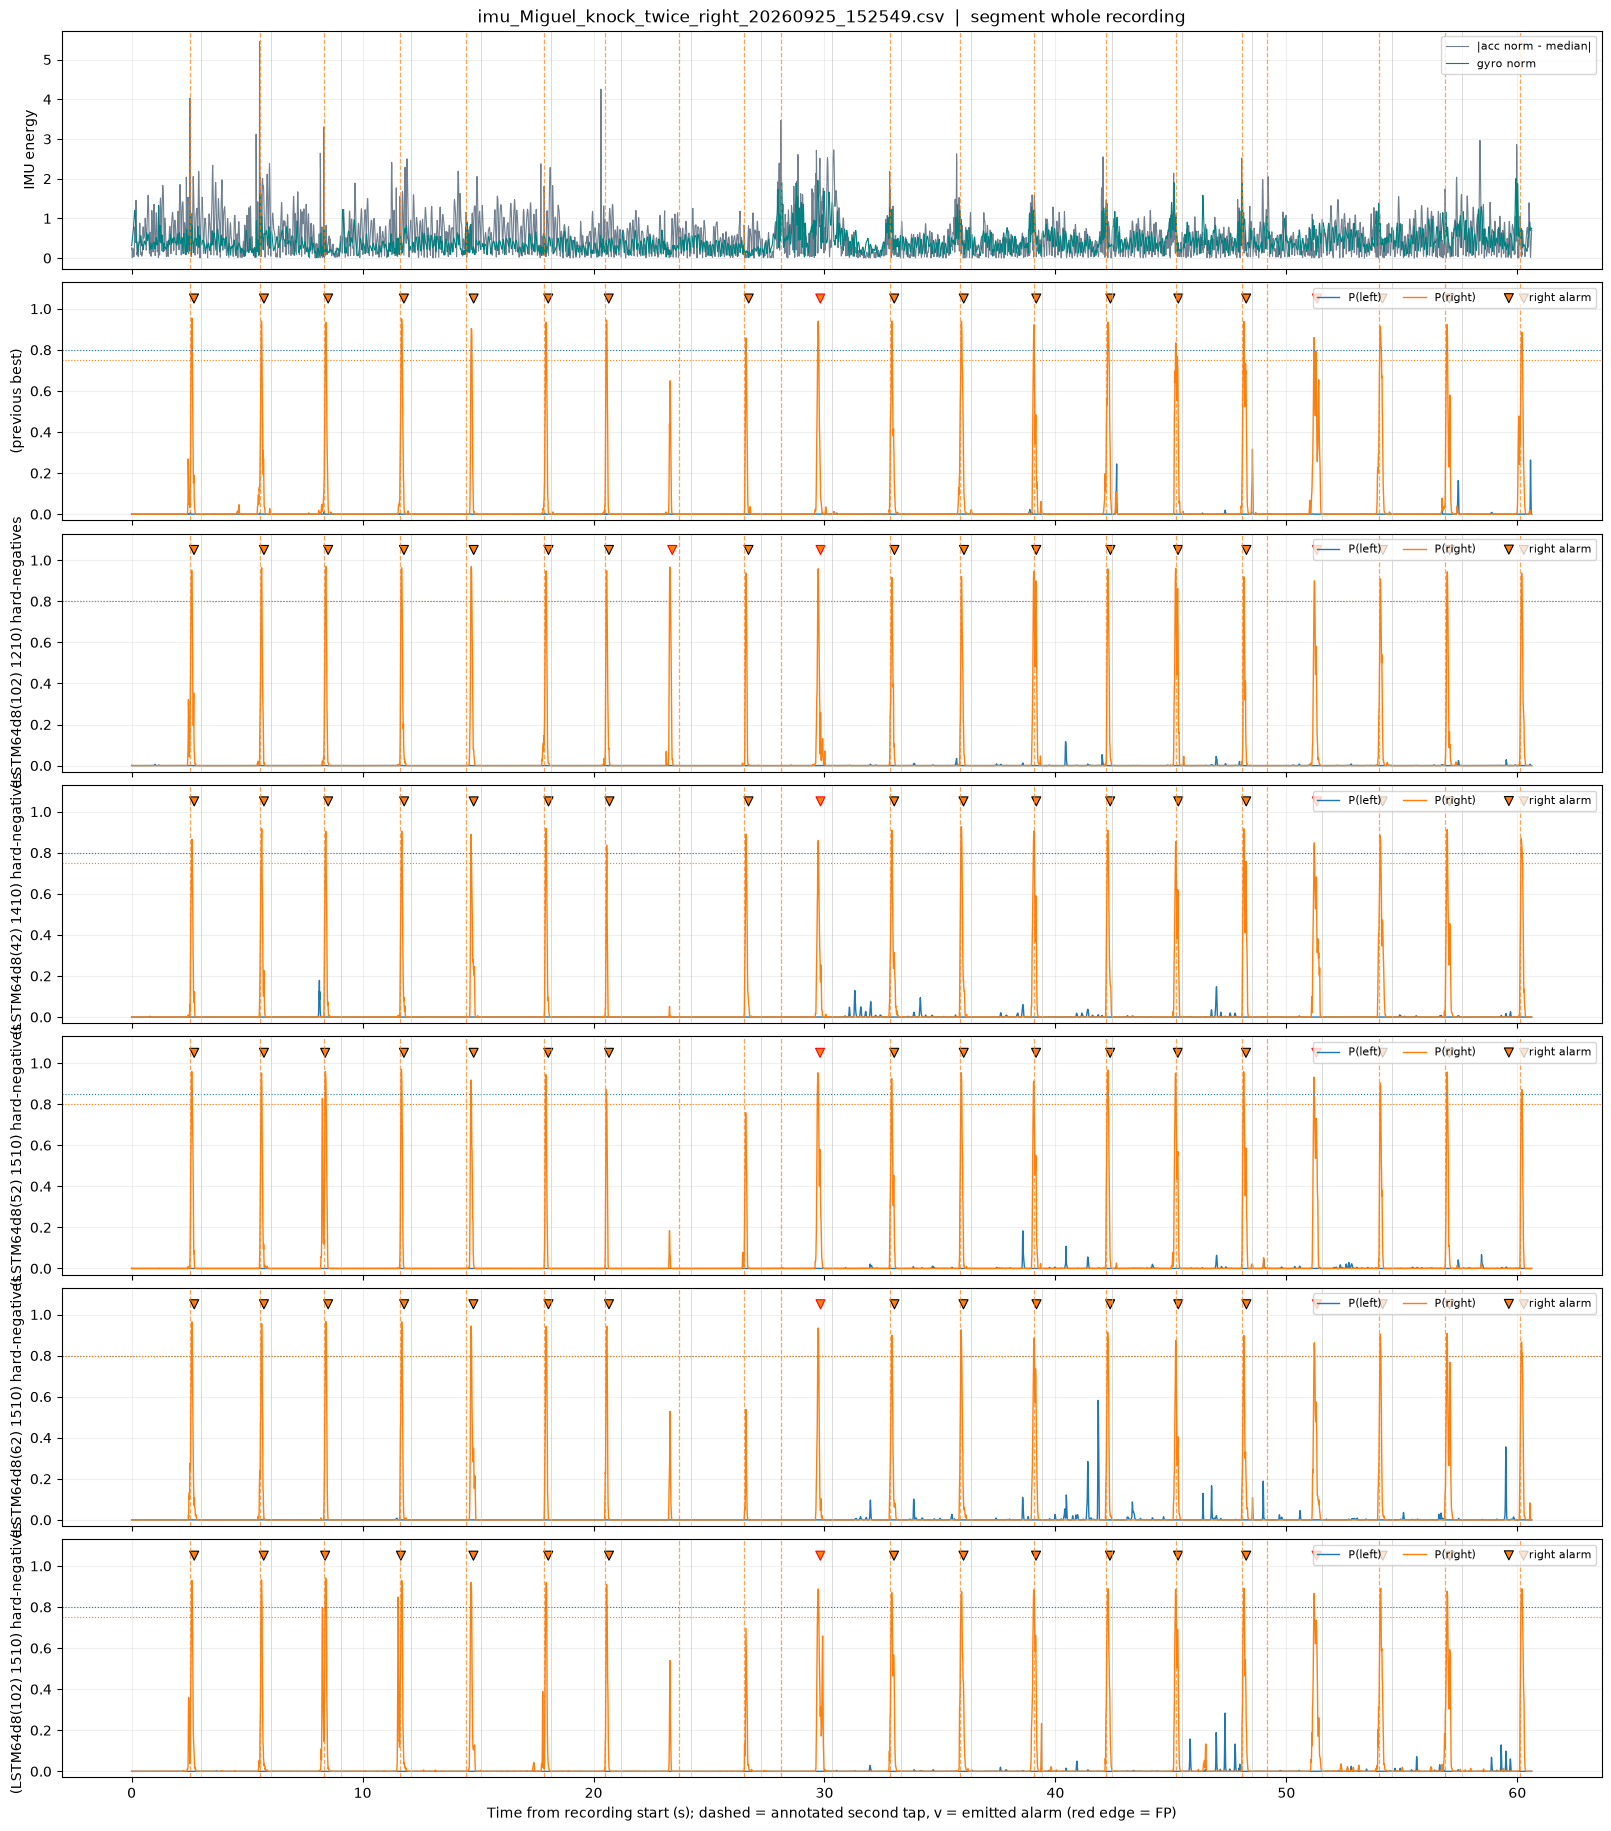

In [19]:
# Replace these values with a file and segment_index from segment_difficulty.
hardest = segment_difficulty.query("recording_type == 'knock_twice'").sort_values(
    ['models_missing', 'too_early_fp', 'models_false_alarm'], ascending=False).iloc[0]
REVIEW_FILE = hardest['file']
# REVIEW_SEGMENT = int(hardest['segment_index'])  # None = whole recording
# REVIEW_FILE = 'imu_Miguel_negative_mining_20261009_172016__crop_f000932_f001232.csv'
REVIEW_SEGMENT = None
display(segment_scores.query('file == @REVIEW_FILE and segment_index == @REVIEW_SEGMENT')
        [['model', 'file', 'segment_index', 'window_true', 'window_pred',
          'event_tp', 'event_fp', 'event_fn', 'too_early_fp', 'latency_frames']])
fig, axes = plot_example(example_recordings, example_traces, alarm_details,
                         detail_points, REVIEW_FILE, REVIEW_SEGMENT)
plt.show()

## Inspect individual training examples (current recordings)
Replay the same selected checkpoints on their **current training files**, using the validation-selected thresholds and alarm policy from `detail_points`. High-pass filtering, window fitting, exclusions, and physical second-tap annotations are handled as in the validation inspection. Inference uses eval mode with no amplitude augmentation; no weights or thresholds are updated.

The `train_*` tables and traces support label review on examples used for fitting the models. Agreement across models, a probability peak away from the annotation, or an unusual rhythm can identify review candidates. Agreement is a clue rather than ground truth: these models share the training labels and can learn the same annotation error. Inspect the raw signal and neighboring segments before deciding whether a physical second-tap label is wrong.

`train_example_data_status` records the current training-data hash; it is not compared with a validation export hash. The replay uses current exclusions, so excluded sessions are absent. Segment IDs come from the CSV's `segment_index`.

In [20]:
train_example_recordings, train_example_traces, train_segment_scores, train_recording_scores, train_alarm_details, train_example_data_status = (
    replay_examples(ROOT, detail_points, split='train', source_dir=MINING_SOURCE_DIR)
)
display(train_example_data_status)
print('Training replay:', len(train_segment_scores), 'model/segment rows,',
      len(train_recording_scores), 'model/recording rows,', len(train_alarm_details), 'alarms')

KeyboardInterrupt: 

### Find difficult segments and recordings for training examples
`train_segment_scores`, `train_recording_scores`, and `train_alarm_details` have the same inspection fields as the validation tables. `train_segment_matrix` and `train_recording_matrix` align models side by side. `train_segment_difficulty` adds `n_models` and `models_detecting` to the error counts so you can filter for shared disagreements. For example, use `.query('models_missing == n_models or models_false_alarm == n_models')` to find segments where every model has a missed annotation or an unmatched alarm. These counts do not establish that the models selected the same physical moment; inspect the aligned plots for timing agreement.

Use `train_segment_scores.query("recording_type == 'knock_twice' and event_fn > 0")` for missed taps, or `.query('event_fp > 0')` for unmatched alarms in positive or negative recordings. `train_alarm_details` includes original global peak/emission frames and the closest annotation. Window classification is separate from continuous alarm matching.

In [ ]:
train_segment_matrix = comparison_matrix(train_segment_scores, ['file', 'segment_index'],
    ['window_true', 'window_pred', 'window_correct', 'window_fp', 'window_fn',
     'p_left_max', 'p_right_max', 'event_tp', 'event_fp', 'event_fn',
     'too_early_fp', 'wrong_side_fp', 'latency_frames'])
train_recording_matrix = comparison_matrix(train_recording_scores, ['file'],
    ['recording_type', 'minutes', 'n_windows', 'window_accuracy', 'window_fp', 'window_fn',
     'n_true_events', 'event_tp', 'event_fp', 'event_fn', 'too_early_fp',
     'wrong_side_fp', 'event_fp_per_min'])
train_segment_difficulty = train_segment_scores.groupby(
    ['file', 'segment_index', 'recording_type'], as_index=False).agg(
        n_models=('model', 'nunique'), n_true_events=('n_true_events', 'first'),
        models_detecting=('n_alarms', lambda x: (x > 0).sum()),
        models_missing=('event_fn', lambda x: (x > 0).sum()),
        models_false_alarm=('event_fp', lambda x: (x > 0).sum()),
        models_window_wrong=('window_correct', lambda x: (x == False).sum()),
        too_early_fp=('too_early_fp', 'sum'), wrong_side_fp=('wrong_side_fp', 'sum'))
with pd.option_context('display.max_colwidth', None):
    print('Hard training double-tap segments (one row per CSV segment):')
    display(train_segment_difficulty.query("recording_type == 'knock_twice'")
            .sort_values(['models_missing', 'too_early_fp', 'models_false_alarm'],
                         ascending=False).head(25))
    print('Training segments with shared annotation disagreements:')
    display(train_segment_difficulty.query(
        'models_missing == n_models or models_false_alarm == n_models')
        .sort_values(['models_missing', 'models_false_alarm'], ascending=False).head(25))
    print('Hard training recordings (one row per model/recording):')
    display(train_recording_scores.sort_values(['event_fp_per_min', 'event_fn'], ascending=False)
            [['model', 'file', 'recording_type', 'n_true_events', 'event_tp', 'event_fp',
              'event_fn', 'too_early_fp', 'window_fp', 'event_fp_per_min']].head(25))

Hard training double-tap segments (one row per CSV segment):


,file,segment_index,recording_type,n_models,n_true_events,models_detecting,models_missing,models_false_alarm,models_window_wrong,too_early_fp,wrong_side_fp
343,imuStrict_Miguel_knock_twice_left_20261006_094941.csv,4,knock_twice,6,1,0,6,0,6,0,0
1538,imu_Miguel_knock_twice_left_20260925_152309.csv,19,knock_twice,6,1,5,4,5,1,0,0
1536,imu_Miguel_knock_twice_left_20260925_152309.csv,17,knock_twice,6,1,6,3,5,0,0,0
159,imuStrict_Miguel_knock_twice_left_20260930_103727.csv,20,knock_twice,6,1,3,3,0,3,0,0
1629,imu_Miguel_knock_twice_right_20260923_113114.csv,10,knock_twice,6,1,6,2,6,0,0,0
95,imuStrict_Miguel_knock_twice_left_20260929_152105.csv,16,knock_twice,6,1,4,2,2,2,0,0
761,imuStrict_Miguel_knock_twice_right_20261013_104354.csv,2,knock_twice,6,1,5,2,1,1,0,0
380,imuStrict_Miguel_knock_twice_left_20261013_105119.csv,1,knock_twice,6,1,4,2,0,2,0,0
381,imuStrict_Miguel_knock_twice_left_20261013_105119.csv,2,knock_twice,6,1,4,2,0,2,0,0
387,imuStrict_Miguel_knock_twice_left_20261013_105119.csv,8,knock_twice,6,1,4,2,0,2,0,0


Training segments with shared annotation disagreements:


,file,segment_index,recording_type,n_models,n_true_events,models_detecting,models_missing,models_false_alarm,models_window_wrong,too_early_fp,wrong_side_fp
343,imuStrict_Miguel_knock_twice_left_20261006_094941.csv,4,knock_twice,6,1,0,6,0,6,0,0
1629,imu_Miguel_knock_twice_right_20260923_113114.csv,10,knock_twice,6,1,6,2,6,0,0,0
1494,imu_Miguel_knock_twice_left_20260924_093125.csv,15,knock_twice,6,1,6,1,6,0,0,0
1505,imu_Miguel_knock_twice_left_20260925_105524.csv,6,knock_twice,6,1,6,1,6,0,0,0
1512,imu_Miguel_knock_twice_left_20260925_105524.csv,13,knock_twice,6,1,6,1,6,0,0,0
1515,imu_Miguel_knock_twice_left_20260925_105524.csv,16,knock_twice,6,1,6,1,6,0,0,0
1518,imu_Miguel_knock_twice_left_20260925_105524.csv,19,knock_twice,6,1,6,1,6,0,0,0
1520,imu_Miguel_knock_twice_left_20260925_152309.csv,1,knock_twice,6,1,6,1,6,0,0,0
1529,imu_Miguel_knock_twice_left_20260925_152309.csv,10,knock_twice,6,1,6,1,6,0,0,0
1712,imu_Miguel_knock_twice_right_20260925_105401.csv,13,knock_twice,6,1,6,1,6,0,0,0


Hard training recordings (one row per model/recording):


,model,file,recording_type,n_true_events,event_tp,event_fp,event_fn,too_early_fp,window_fp,event_fp_per_min
3826,(previous best),imu_Miguel_negative_mining_20261009_164938__crop_f002253_f002553.csv,hard_negative,0,0,1,0,0,1.0,26.991003
3832,(previous best),imu_Miguel_negative_mining_20261009_164938__crop_f003304_f003604.csv,hard_negative,0,0,1,0,0,1.0,26.991003
3836,(previous best),imu_Miguel_negative_mining_20261009_164938__crop_f003993_f004293.csv,hard_negative,0,0,1,0,0,1.0,26.991003
3837,(previous best),imu_Miguel_negative_mining_20261009_164938__crop_f004120_f004420.csv,hard_negative,0,0,1,0,0,1.0,26.991003
3848,(previous best),imu_Miguel_negative_mining_20261009_164938__crop_f005702_f006002.csv,hard_negative,0,0,1,0,0,1.0,26.991003
4452,(previous best),imu_Miguel_switch_doubletap_20261012_170616.csv,switch_doubletap,0,0,21,0,0,16.0,20.854022
560,(LSTM64d8(102) 1210) hard-negatives,imu_Miguel_normal_usage_20261014_092309__crop_f023146_f023446.csv,hard_negative,0,0,2,0,0,1.0,20.799307
179,(LSTM64d8(102) 1210) hard-negatives,imu_Miguel_negative_mining_20261009_173627__crop_f002053_f002353.csv,hard_negative,0,0,1,0,0,1.0,20.006669
180,(LSTM64d8(102) 1210) hard-negatives,imu_Miguel_negative_mining_20261009_173627__crop_f002323_f002623.csv,hard_negative,0,0,1,0,0,1.0,20.006669
921,(LSTM64d8(102) 1510) hard-negatives,imu_Miguel_negative_mining_20261009_173627__crop_f000268_f000568.csv,hard_negative,0,0,1,0,0,1.0,20.006669


### Aligned recording/segment inspection on training examples
Choose `TRAIN_REVIEW_FILE` and `TRAIN_REVIEW_SEGMENT` from `train_segment_difficulty`. The default selects a difficult training double-tap segment; set `TRAIN_REVIEW_SEGMENT = None` to inspect the entire recording and compare the rhythm with neighboring sessions. The raw IMU row, annotated physical second taps, model probabilities, thresholds, and emitted alarms share the original recording's time axis. Training-target delay is not added to the annotation markers.

For tabular inspection of all models together, use `train_segment_matrix.loc[('filename.csv', 8)]` or `train_recording_matrix.loc['filename.csv']`. To check an individual alarm, filter `train_alarm_details` by file and segment.

,model,file,segment_index,window_true,window_pred,event_tp,event_fp,event_fn,too_early_fp,latency_frames
1300,(previous best),imu_Miguel_knock_once_20261009_103349.csv,1,0.0,0.0,0,0,0,0,NaN
1301,(previous best),imu_Miguel_knock_once_20261009_103349.csv,2,0.0,1.0,0,1,0,0,NaN
1302,(previous best),imu_Miguel_knock_once_20261009_103349.csv,3,0.0,1.0,0,1,0,0,NaN
1303,(previous best),imu_Miguel_knock_once_20261009_103349.csv,4,0.0,0.0,0,0,0,0,NaN
1304,(previous best),imu_Miguel_knock_once_20261009_103349.csv,5,0.0,0.0,0,0,0,0,NaN
...,...,...,...,...,...,...,...,...,...,...
18350,(LSTM64d8(102) 1510) hard-negatives,imu_Miguel_knock_once_20261009_103349.csv,16,0.0,0.0,0,0,0,0,NaN
18351,(LSTM64d8(102) 1510) hard-negatives,imu_Miguel_knock_once_20261009_103349.csv,17,0.0,0.0,0,0,0,0,NaN
18352,(LSTM64d8(102) 1510) hard-negatives,imu_Miguel_knock_once_20261009_103349.csv,18,0.0,0.0,0,0,0,0,NaN
18353,(LSTM64d8(102) 1510) hard-negatives,imu_Miguel_knock_once_20261009_103349.csv,19,0.0,0.0,0,0,0,0,NaN


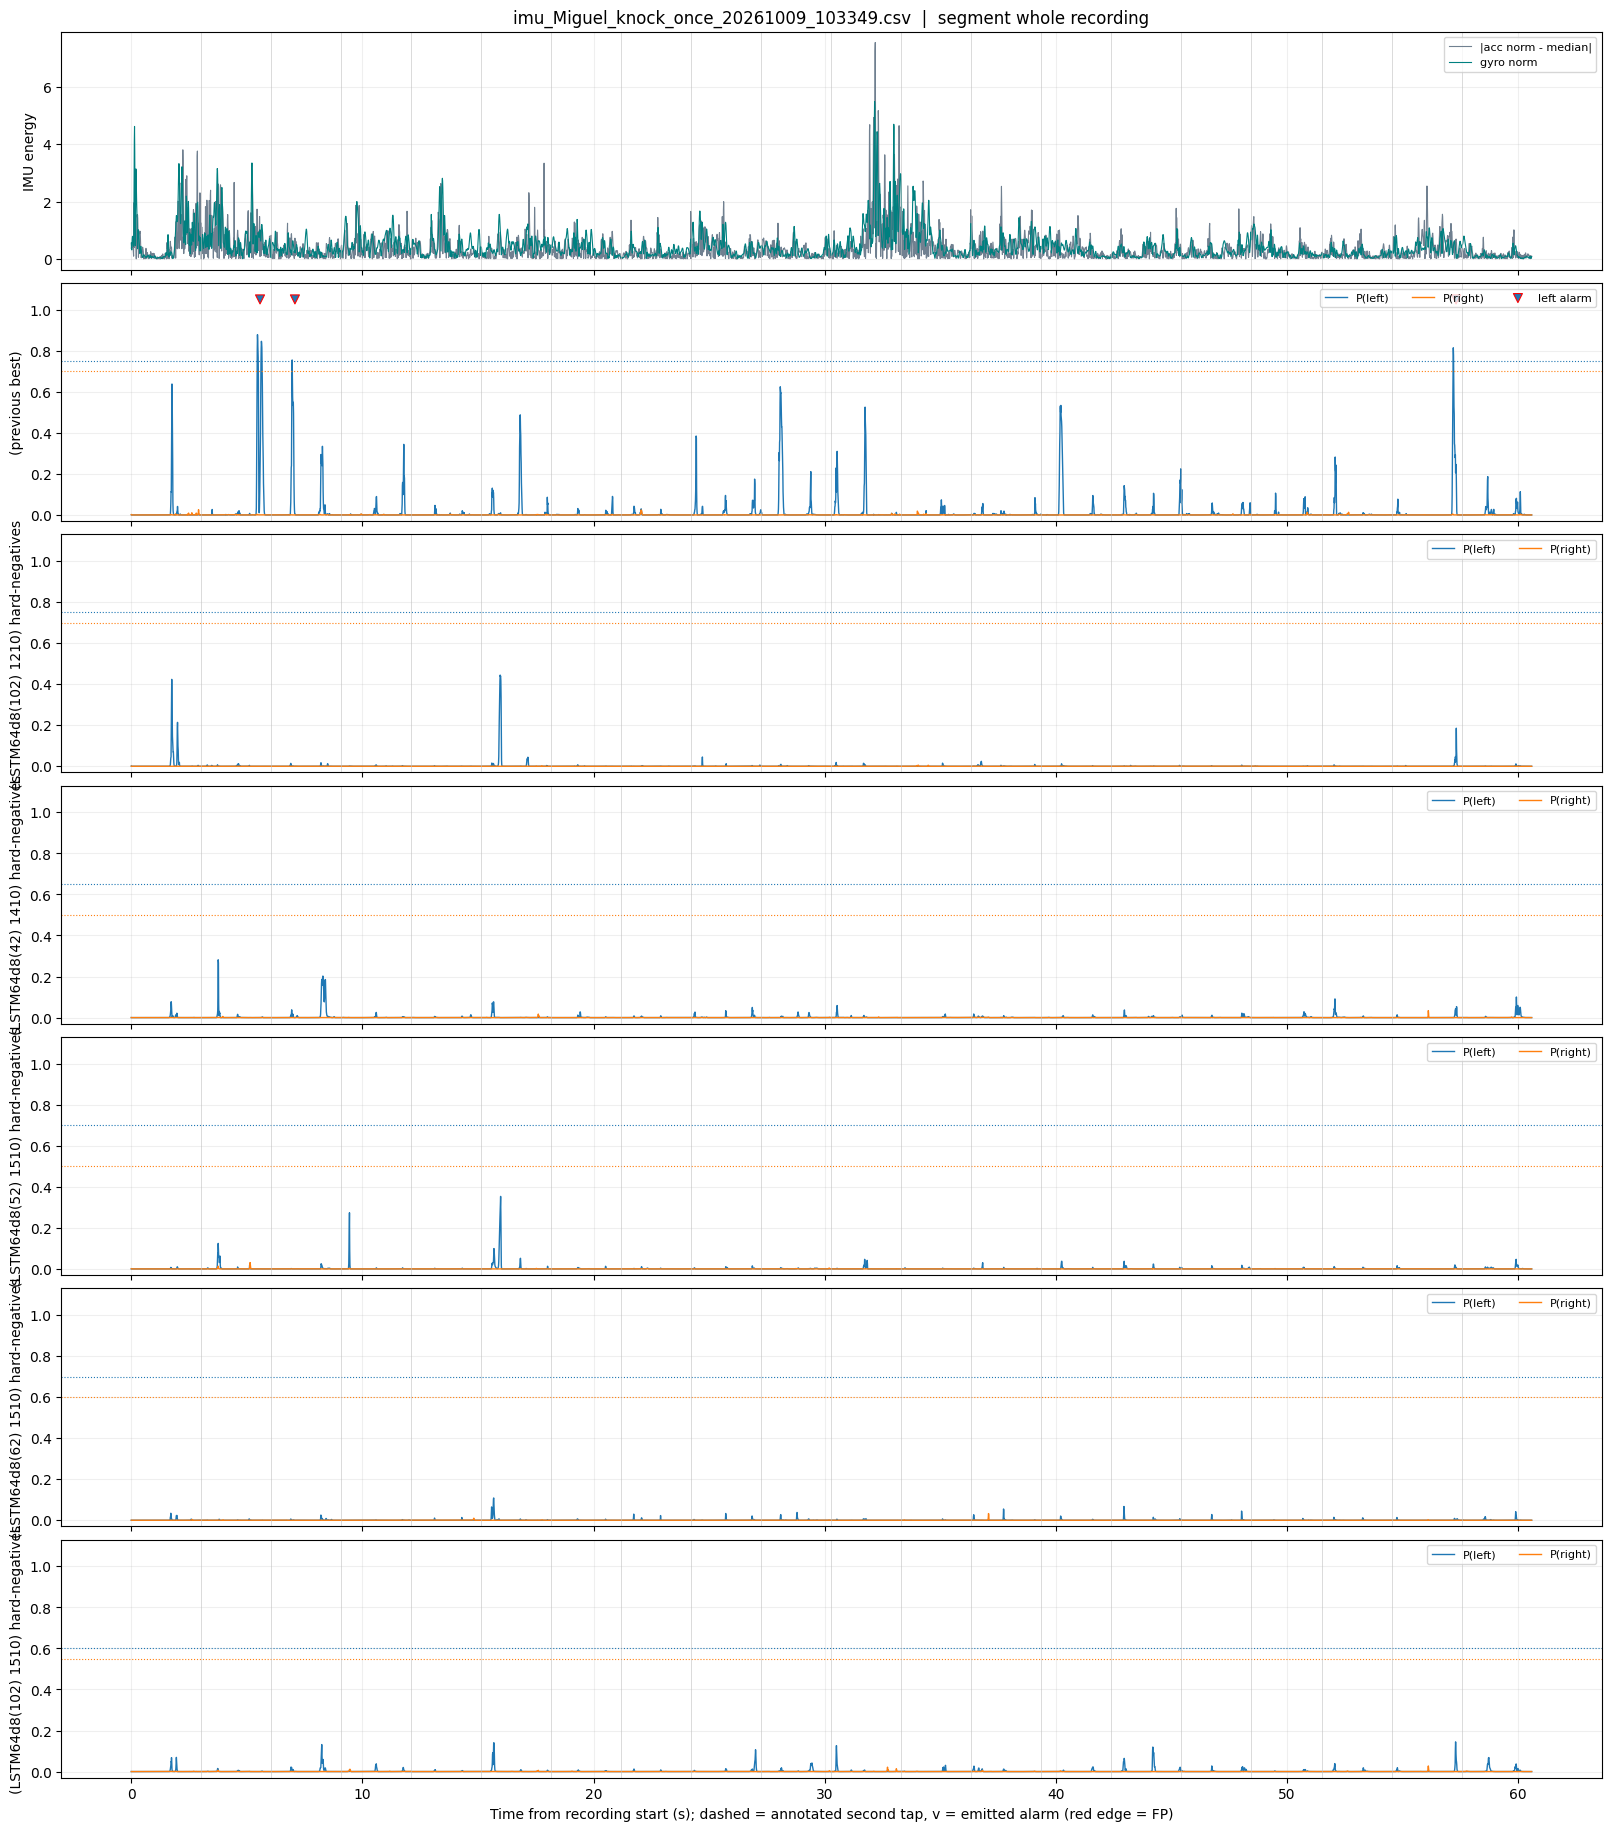

In [ ]:
train_review_candidates = train_segment_difficulty.query("recording_type == 'knock_twice'")
if train_review_candidates.empty:
    train_review_candidates = train_segment_difficulty
train_hardest = train_review_candidates.sort_values(
    ['models_missing', 'too_early_fp', 'models_false_alarm'], ascending=False).iloc[0]
# Replace these values with a file and CSV segment_index from the training tables.
TRAIN_REVIEW_FILE = 'imu_Miguel_knock_once_20261009_103349.csv'
TRAIN_REVIEW_SEGMENT = None  # None = whole recording
train_review_rows = train_segment_scores[train_segment_scores.file == TRAIN_REVIEW_FILE]
if TRAIN_REVIEW_SEGMENT is not None:
    train_review_rows = train_review_rows[train_review_rows.segment_index == TRAIN_REVIEW_SEGMENT]
display(train_review_rows[['model', 'file', 'segment_index', 'window_true', 'window_pred',
                         'event_tp', 'event_fp', 'event_fn', 'too_early_fp', 'latency_frames']])
train_fig, train_axes = plot_example(train_example_recordings, train_example_traces, train_alarm_details,
                                    detail_points, TRAIN_REVIEW_FILE, TRAIN_REVIEW_SEGMENT)
plt.show()